# Factors Affecting Students' Mathematics Achievement
**Padjadjaran Statistics Olympiad — Final Round (RASIO)** · Multilevel Analysis (Linear Mixed Models)

> Cell markers: 🔧 = revised from the earlier version, 🆕 = newly added.

## 0. Data Structure and Methodological Framework (🆕)

**Data structure.** There are 900 observations (30 schools × 30 students). Students are *nested* within schools, so the data are **hierarchical with two levels**:

| Level | Unit | Variables |
|---|---|---|
| 1 | Student (i) | `math_score` (Y), `prior_score`, `ses`, `study_hours`, `gender` |
| 2 | School (j) | `facility`, `teacher_exp` (identical for all students within a school) |

**Why not OLS?** Students in the same school share a learning environment, so their scores are correlated (*intraclass correlation*, ICC). This violates the independence assumption of OLS: the standard errors of school-level predictors become too small and conclusions can be misleading. The impact is measured by the *design effect* = 1 + (m − 1)·ICC, where m = 30 students per school.

**Method: Linear Mixed Model with a random school intercept.** For student *i* in school *j*:

$$Y_{ij} = \gamma_{00} + \sum_k \gamma_{k0} X_{kij} + \sum_l \gamma_{0l} W_{lj} + u_{0j} + e_{ij},\quad u_{0j}\sim N(0,\tau_{00}),\; e_{ij}\sim N(0,\sigma^2)$$

| Model | Content | Answers |
|---|---|---|
| **M1 (Null)** | intercept + random intercept only | **Q1**: ICC = τ₀₀ / (τ₀₀ + σ²) |
| **M2** | + student predictors (prior, SES, study hours, gender) | **Q2**: effects of student characteristics; reduction in σ² |
| **M3 (Full)** | + school predictors (facility, teacher_exp) | **Q3**: effects of school characteristics; reduction in τ₀₀ from M2 to M3 |
| test of τ₀₀ in M3 | LRT of mixed model vs OLS | **Q4**: does between-school variation remain unexplained? |

**Technical notes.**
- **REML** is used for final parameter estimates (unbiased variances). **ML** is used when comparing models that differ in fixed effects (AIC, BIC, LRT).
- The test for between-school variance uses a χ² mixture (0.5·χ²₀ + 0.5·χ²₁) because τ₀₀ is tested on the boundary of the parameter space (zero).
- **PVE** (*proportion of variance explained*) is computed separately for each level: (σ²_null − σ²_model)/σ²_null at the student level, and (τ₀₀_null − τ₀₀_model)/τ₀₀_null at the school level. Nakagawa's R² (marginal and conditional) is reported as a complement.
- Continuous predictors are standardized. Student-level variables use the mean and SD of the 900 students; school-level variables use the mean and SD of the 30 schools. Coefficients are read as effects **per 1 SD**.
- Diagnostics: normality of residuals and random effects, homoscedasticity, multicollinearity (VIF), influential schools (*leave-one-school-out*), and random-slope tests.
- **Specification check (a finding):** the random-slope tests show that the effect of `study_hours` differs across schools, so **M4 (M3 + random slope for study_hours)** is added. School-level conclusions are compared across several specifications (robustness check).

In [1]:
# !pip install statsmodels seaborn -q   # usually already available in Colab
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy import stats
import glob, warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
pd.set_option('display.width', 200)

def fp(p):
    """Format a p-value: avoid printing 0."""
    return "<0.001" if p < 0.001 else f"{p:.3f}"

print("✅ Libraries ready.")

✅ Libraries ready.


## 1. Data and Preprocessing

In [2]:
# 🔧 Cell 2: message matches the file format (.xlsx), with a fallback when run outside Colab
try:
    from google.colab import files
    print("Please upload 'Final Round Data.xlsx'")
    uploaded = files.upload()
    path = next(iter(uploaded))
except ImportError:
    path = glob.glob('*Final*Data*.xlsx')[0]
    print("Reading local file:", path)
df = pd.read_excel(path)
df.head()

Reading local file: Final Round Data.xlsx


,school_id,student_id,gender,ses,study.hours,prior.score,facility,teacher.exp,math.score
0,1,S01_01,Perempuan,33.700,9.300,61.900,69.200,10.400,70.000
1,1,S01_02,Laki-laki,82.200,13.100,61.500,69.200,10.400,94.400
2,1,S01_03,Laki-laki,68.900,7.300,79.300,69.200,10.400,90.400
3,1,S01_04,Laki-laki,42.900,8.200,49.500,69.200,10.400,72.400
4,1,S01_05,Laki-laki,70.700,5.500,66.800,69.200,10.400,87.700


In [3]:
# 🔧 Cell 3: school-level variables are standardized using the mean/SD of the 30 schools (not the 900 students)
df = df.rename(columns={
    'study.hours':'study_hours', 'prior.score':'prior_score',
    'math.score':'math_score',  'teacher.exp':'teacher_exp'
})

print("="*65); print("1. PREPROCESSING"); print("="*65)
print(f"Shape                : {df.shape}")
print(f"Missing values       : {df.isnull().sum().sum()}")
print(f"Duplicates           : {df.duplicated().sum()}")
print(f"Number of schools    : {df['school_id'].nunique()}")
print(f"Students per school  : {df.groupby('school_id').size().unique()}")

# Confirm facility & teacher_exp really are school-level variables (constant within school)
chk = df.groupby('school_id')[['facility','teacher_exp']].nunique()
print(f"Unique facility/teacher_exp values per school (must be 1): max = {chk.max().max()}")

df['gender_male'] = (df['gender'] == 'Laki-laki').astype(int)   # 'Laki-laki' = male in the raw data
df['school_id']   = df['school_id'].astype('category')

# Student level: z-scores from the 900 students
for v in ['ses','study_hours','prior_score']:
    df[f'{v}_z'] = (df[v] - df[v].mean()) / df[v].std()

# School level: z-scores from the 30 schools
sch = df.groupby('school_id', observed=True)[['facility','teacher_exp']].first()
for v in ['facility','teacher_exp']:
    df[f'{v}_z'] = (df[v] - sch[v].mean()) / sch[v].std()

print("\nDescriptive statistics:")
print(df[['math_score','prior_score','ses','study_hours','facility','teacher_exp']].describe().T.round(2))

1. PREPROCESSING
Shape                : (900, 9)
Missing values       : 0
Duplicates           : 0
Number of schools    : 30
Students per school  : [30]
Unique facility/teacher_exp values per school (must be 1): max = 1

Descriptive statistics:
              count   mean    std    min    25%    50%    75%    max
math_score  900.000 77.790  6.200 57.900 73.500 78.100 81.900 95.900
prior_score 900.000 64.830 10.010 31.300 58.080 64.600 71.700 95.000
ses         900.000 49.580 12.200 16.900 41.100 49.200 57.920 83.900
study_hours 900.000  7.930  2.510  1.000  6.200  8.000  9.520 16.100
facility    900.000 69.540 10.110 47.100 61.400 69.100 76.500 91.000
teacher_exp 900.000  9.360  3.010  3.500  6.900  9.350 11.500 15.000


## 2. Exploratory Data Analysis

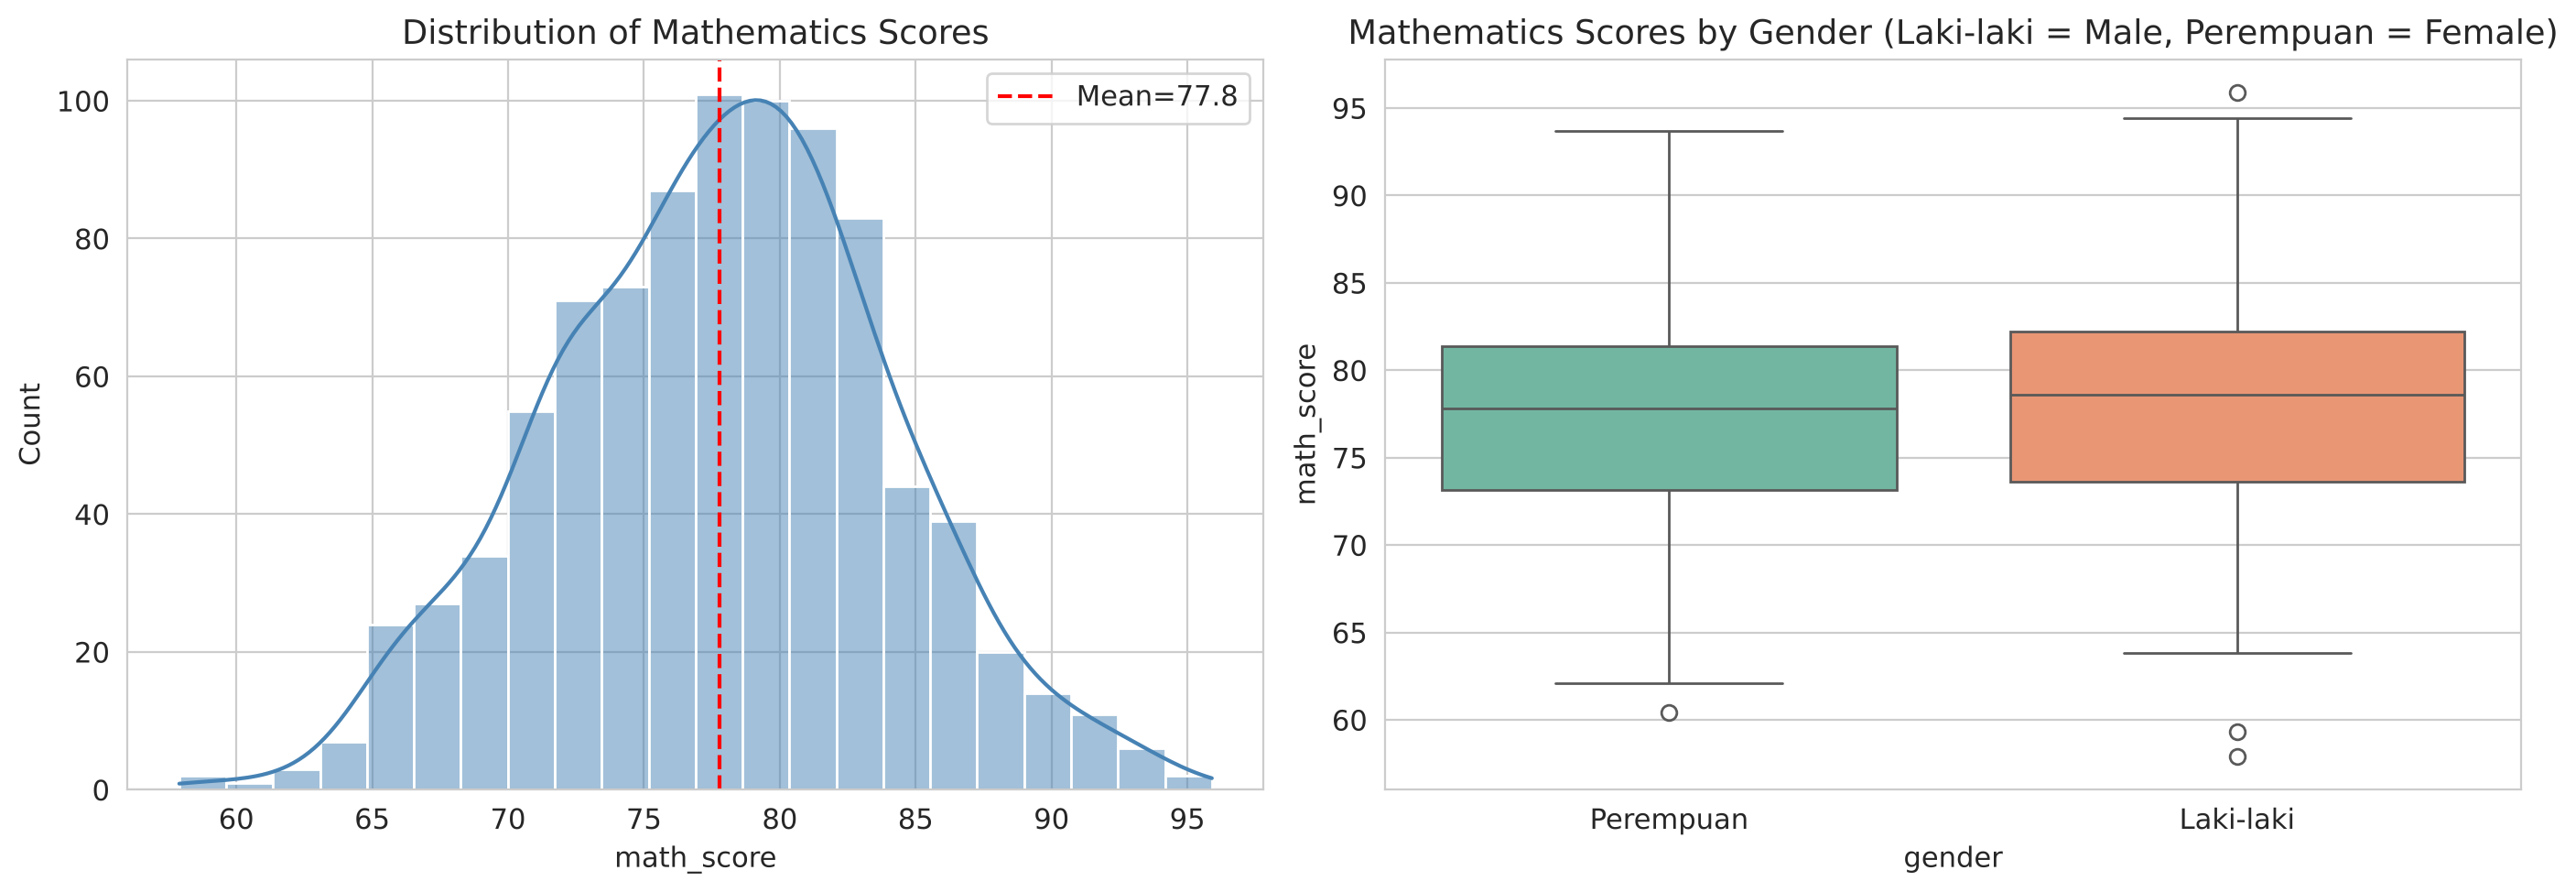

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))
sns.histplot(df['math_score'], kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Distribution of Mathematics Scores')
axes[0].axvline(df['math_score'].mean(), color='red', ls='--',
                label=f"Mean={df['math_score'].mean():.1f}")
axes[0].legend()
sns.boxplot(data=df, x='gender', y='math_score', ax=axes[1], palette='Set2')
axes[1].set_title('Mathematics Scores by Gender (Laki-laki = Male, Perempuan = Female)')
plt.tight_layout(); plt.show()

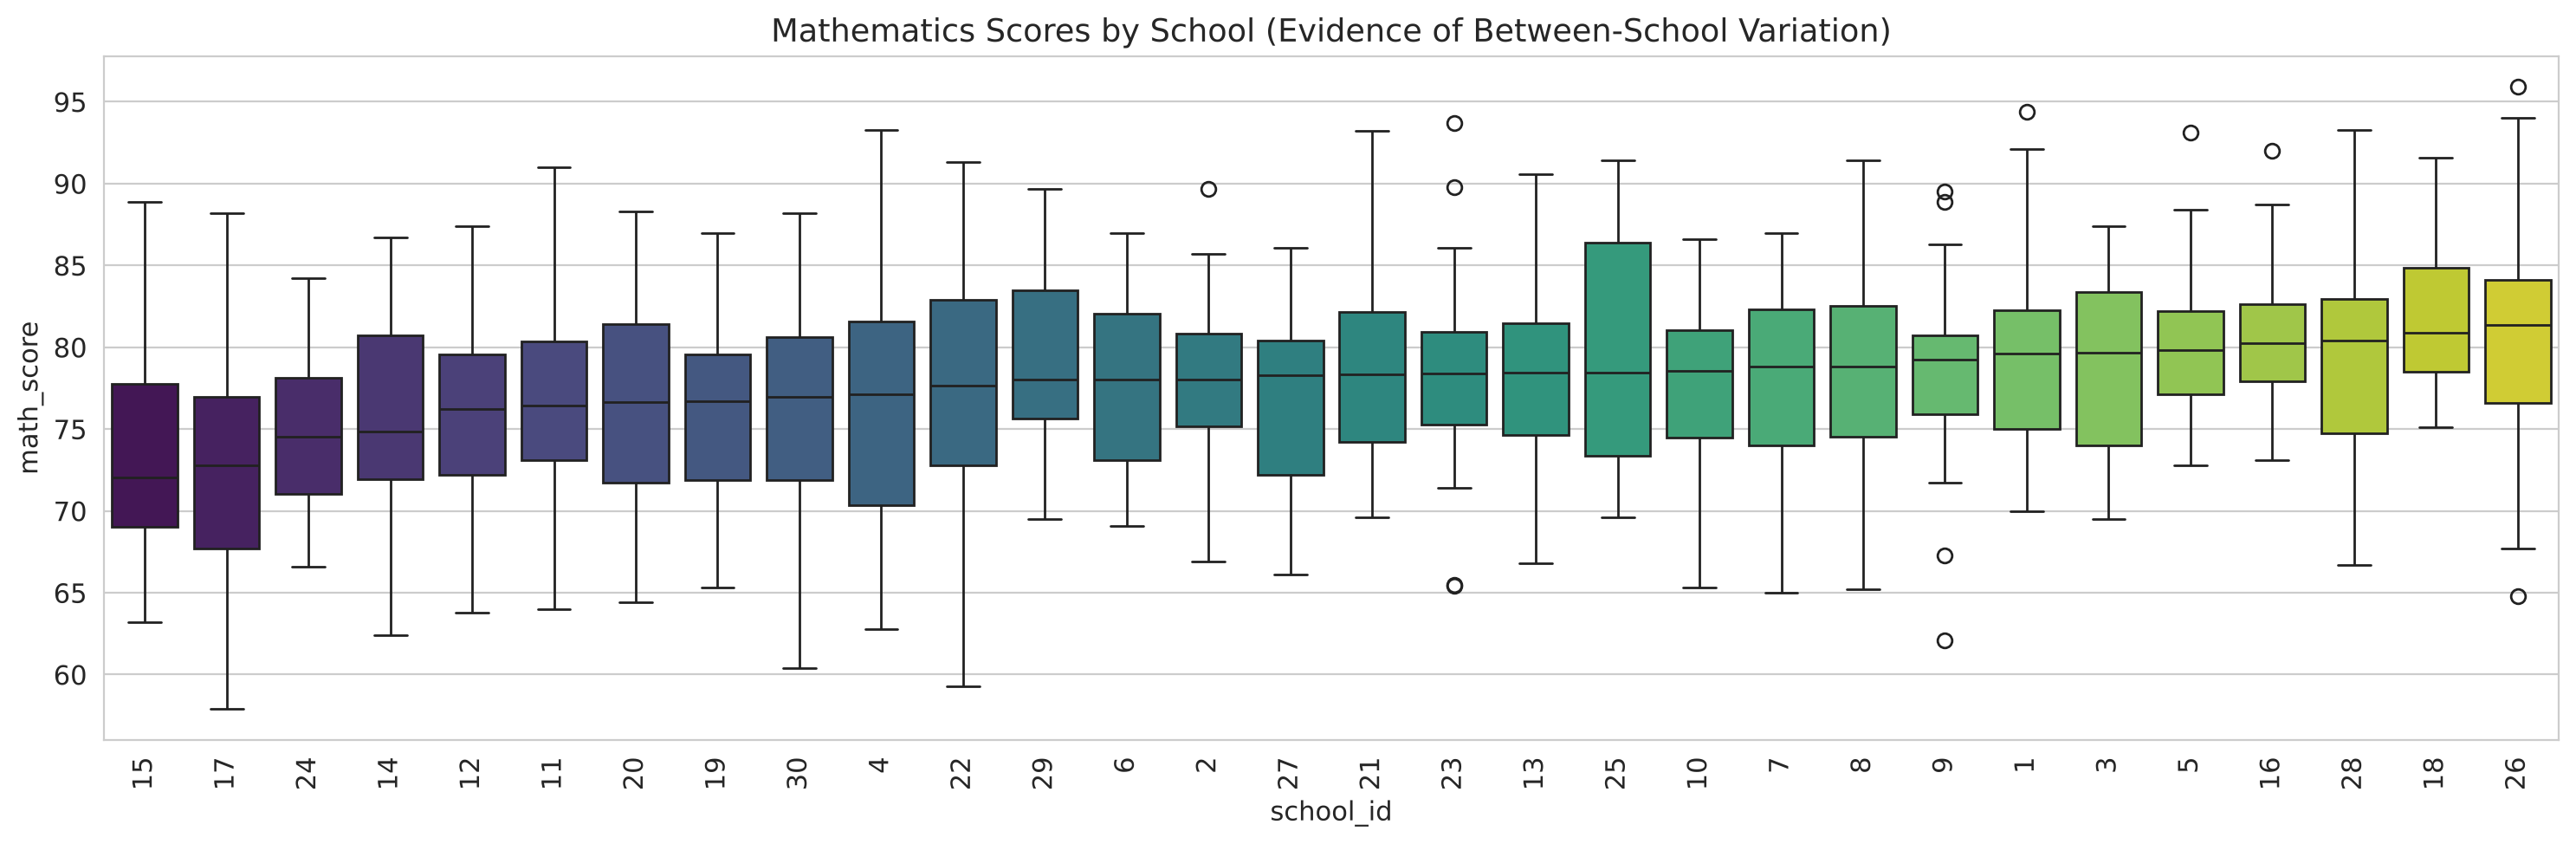

In [5]:
plt.figure(figsize=(15,5))
order = df.groupby('school_id', observed=True)['math_score'].median().sort_values().index
sns.boxplot(data=df, x='school_id', y='math_score', order=order, palette='viridis')
plt.title('Mathematics Scores by School (Evidence of Between-School Variation)')
plt.xticks(rotation=90); plt.tight_layout(); plt.show()

**Interpretation.** Median scores and spread differ across schools, and the schools with the highest and lowest medians are clearly separated. This is an early indication of a school-level variance component, so a multilevel model is warranted.

=== Math score by gender ===
           count   mean   std    min    max
gender                                     
Laki-laki    425 77.970 6.420 57.900 95.900
Perempuan    475 77.620 6.000 60.400 93.700

=== School summary (5 lowest and 5 highest by mean score) ===
           mean_math  sd_math  mean_ses  mean_prior  facility  teacher_exp
school_id                                                                 
17            73.080    6.580    43.660      66.410    78.000        9.800
15            73.780    5.870    46.800      64.110    70.200       10.900
24            74.500    4.870    46.260      64.180    72.900        4.000
14            75.380    6.260    49.320      61.900    69.000        6.000
12            76.010    5.970    49.390      62.870    76.800        5.000
1             79.760    6.200    51.930      63.330    69.200       10.400
5             80.090    4.680    50.950      65.440    66.100        9.000
16            80.590    4.220    51.930      68.770    75

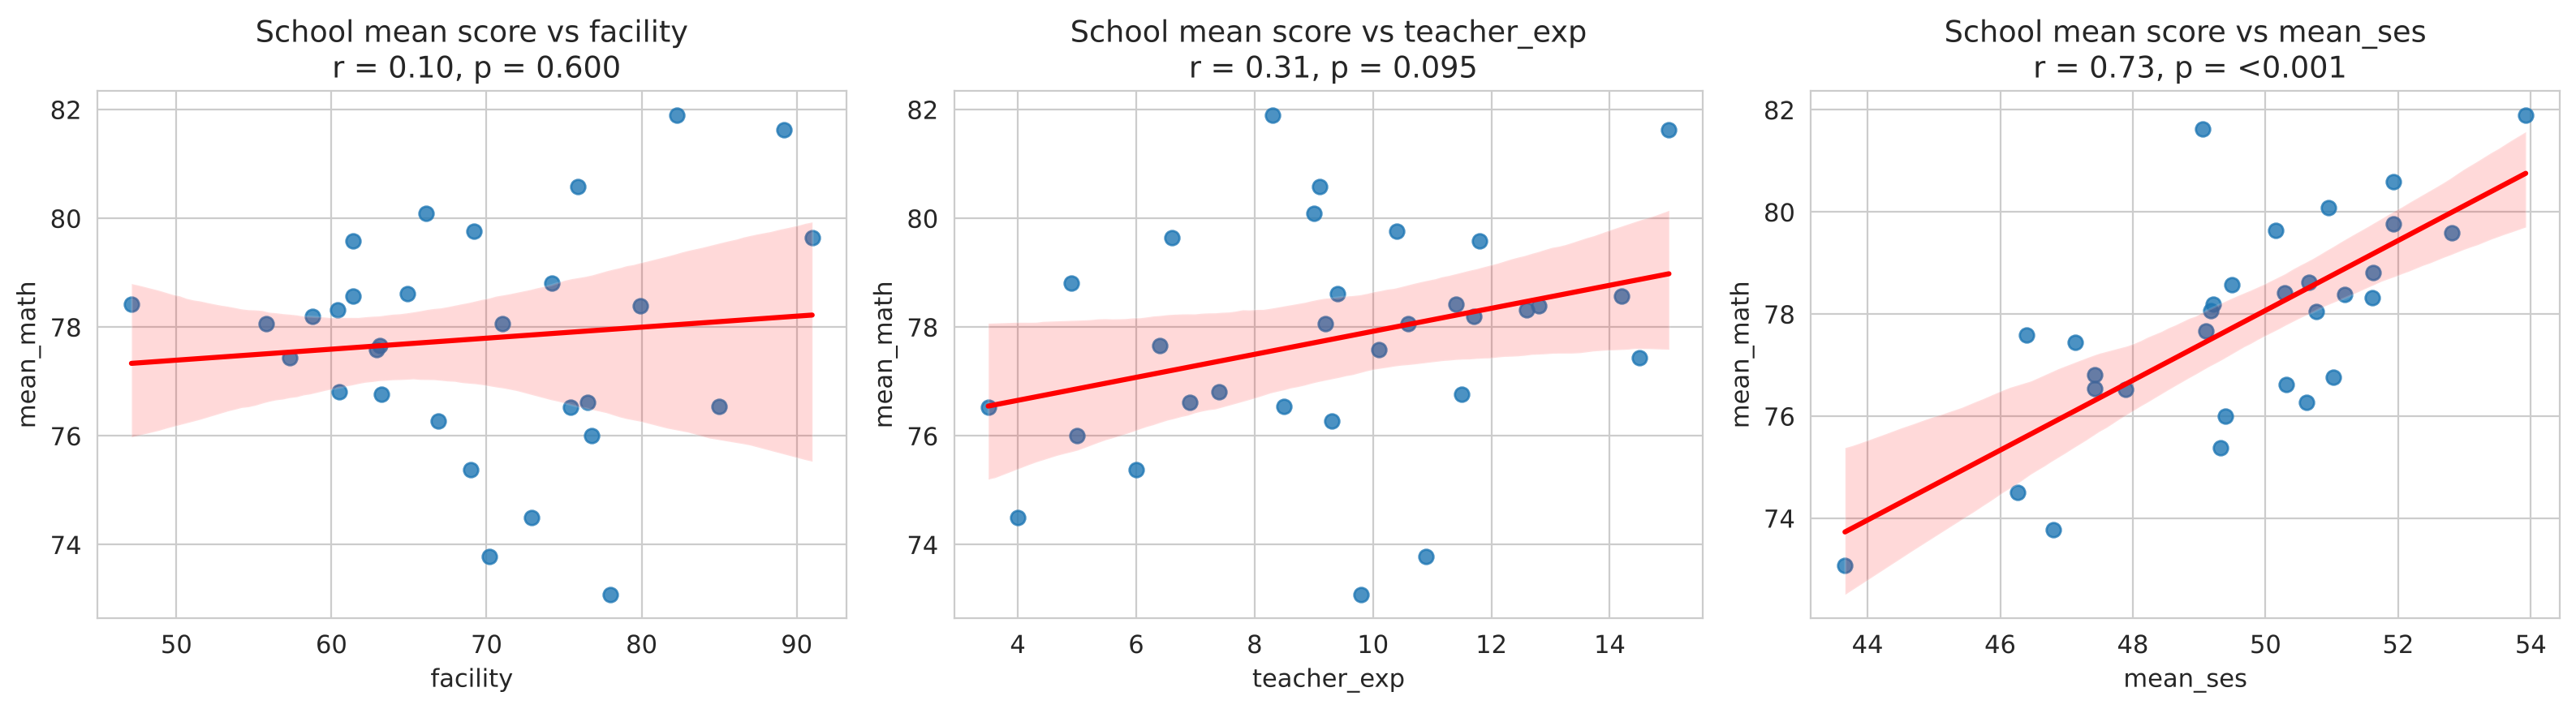

In [6]:
# 🆕 Additional descriptive tables
print("=== Math score by gender ===")
print(df.groupby('gender')['math_score'].agg(['count','mean','std','min','max']).round(2))

school_tbl = (df.groupby('school_id', observed=True)
                .agg(mean_math=('math_score','mean'), sd_math=('math_score','std'),
                     mean_ses=('ses','mean'), mean_prior=('prior_score','mean'),
                     facility=('facility','first'), teacher_exp=('teacher_exp','first')))
print("\n=== School summary (5 lowest and 5 highest by mean score) ===")
srt = school_tbl.sort_values('mean_math')
print(pd.concat([srt.head(5), srt.tail(5)]).round(2))

# 🆕 School-level scatterplots: mean score vs school variables
fig, axes = plt.subplots(1, 3, figsize=(16,4.5))
for ax, v in zip(axes, ['facility','teacher_exp','mean_ses']):
    sns.regplot(data=school_tbl, x=v, y='mean_math', ax=ax,
                scatter_kws={'s':40}, line_kws={'color':'red'})
    r, p = stats.pearsonr(school_tbl[v], school_tbl['mean_math'])
    ax.set_title(f'School mean score vs {v}\n r = {r:.2f}, p = {fp(p)}')
plt.tight_layout(); plt.show()

**Interpretation.** At the school level (n = 30), mean scores appear more strongly related to the mean SES of students than to `facility` or `teacher_exp`. The relationships of facilities and teacher experience with scores look weak to moderate, with many points scattered around the line.

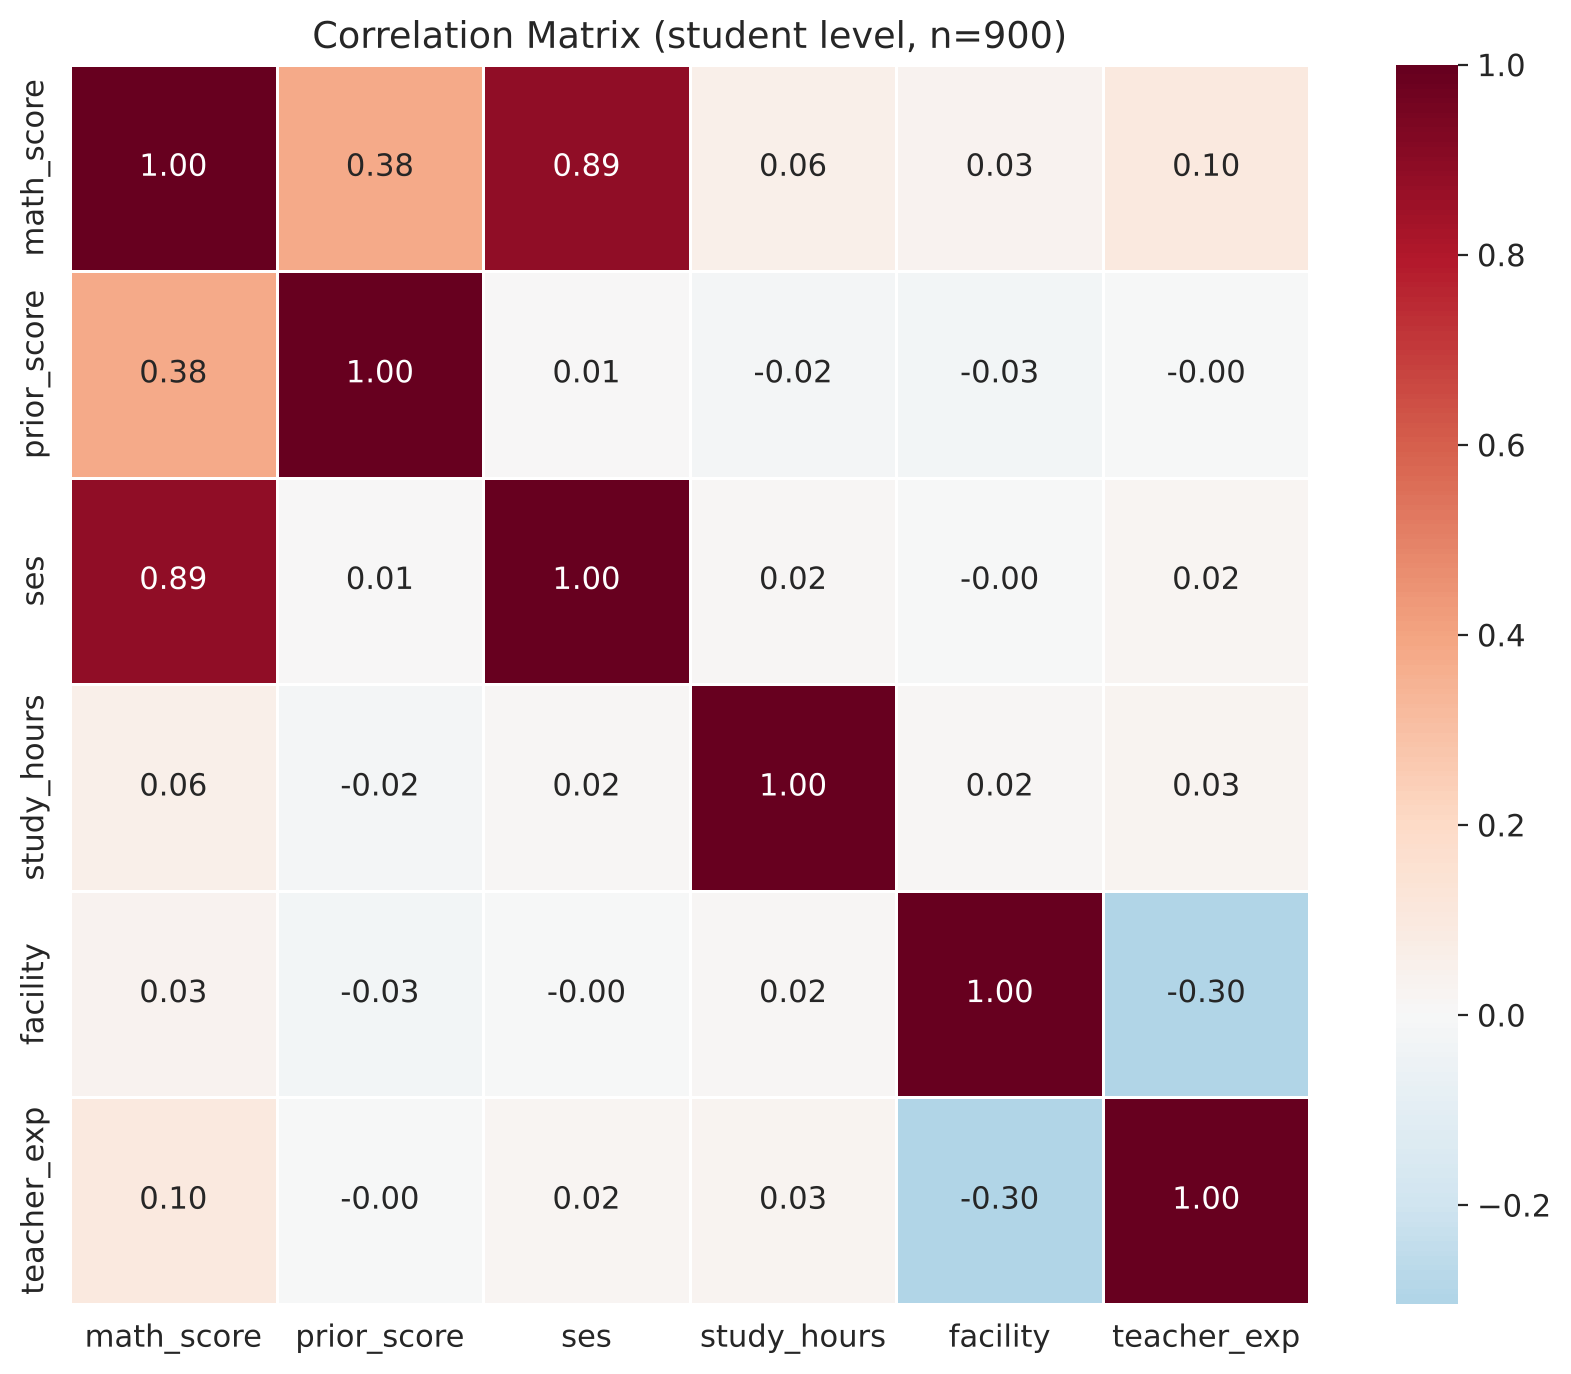


=== VIF (rule of thumb: > 5 is a concern) ===
     Variable   VIF
prior_score_z 1.002
        ses_z 1.001
study_hours_z 1.002
  gender_male 1.001
   facility_z 1.104
teacher_exp_z 1.104

Correlation facility vs teacher_exp (school level, n=30): -0.304


In [7]:
plt.figure(figsize=(9,7))
corr = df[['math_score','prior_score','ses','study_hours','facility','teacher_exp']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, square=True, linewidths=.5)
plt.title('Correlation Matrix (student level, n=900)'); plt.tight_layout(); plt.show()

# 🆕 VIF (multicollinearity)
Xv = sm.add_constant(df[['prior_score_z','ses_z','study_hours_z','gender_male','facility_z','teacher_exp_z']])
vif = pd.DataFrame({'Variable': Xv.columns[1:],
                    'VIF': [variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])]})
print("\n=== VIF (rule of thumb: > 5 is a concern) ===")
print(vif.round(3).to_string(index=False))
print(f"\nCorrelation facility vs teacher_exp (school level, n=30): {sch.corr().iloc[0,1]:.3f}")

**Interpretation.** `ses` has the strongest correlation with mathematics score. All VIF values are close to 1, so there is no multicollinearity problem. `facility` and `teacher_exp` are only weakly correlated at the school level, so their effects can be separated.

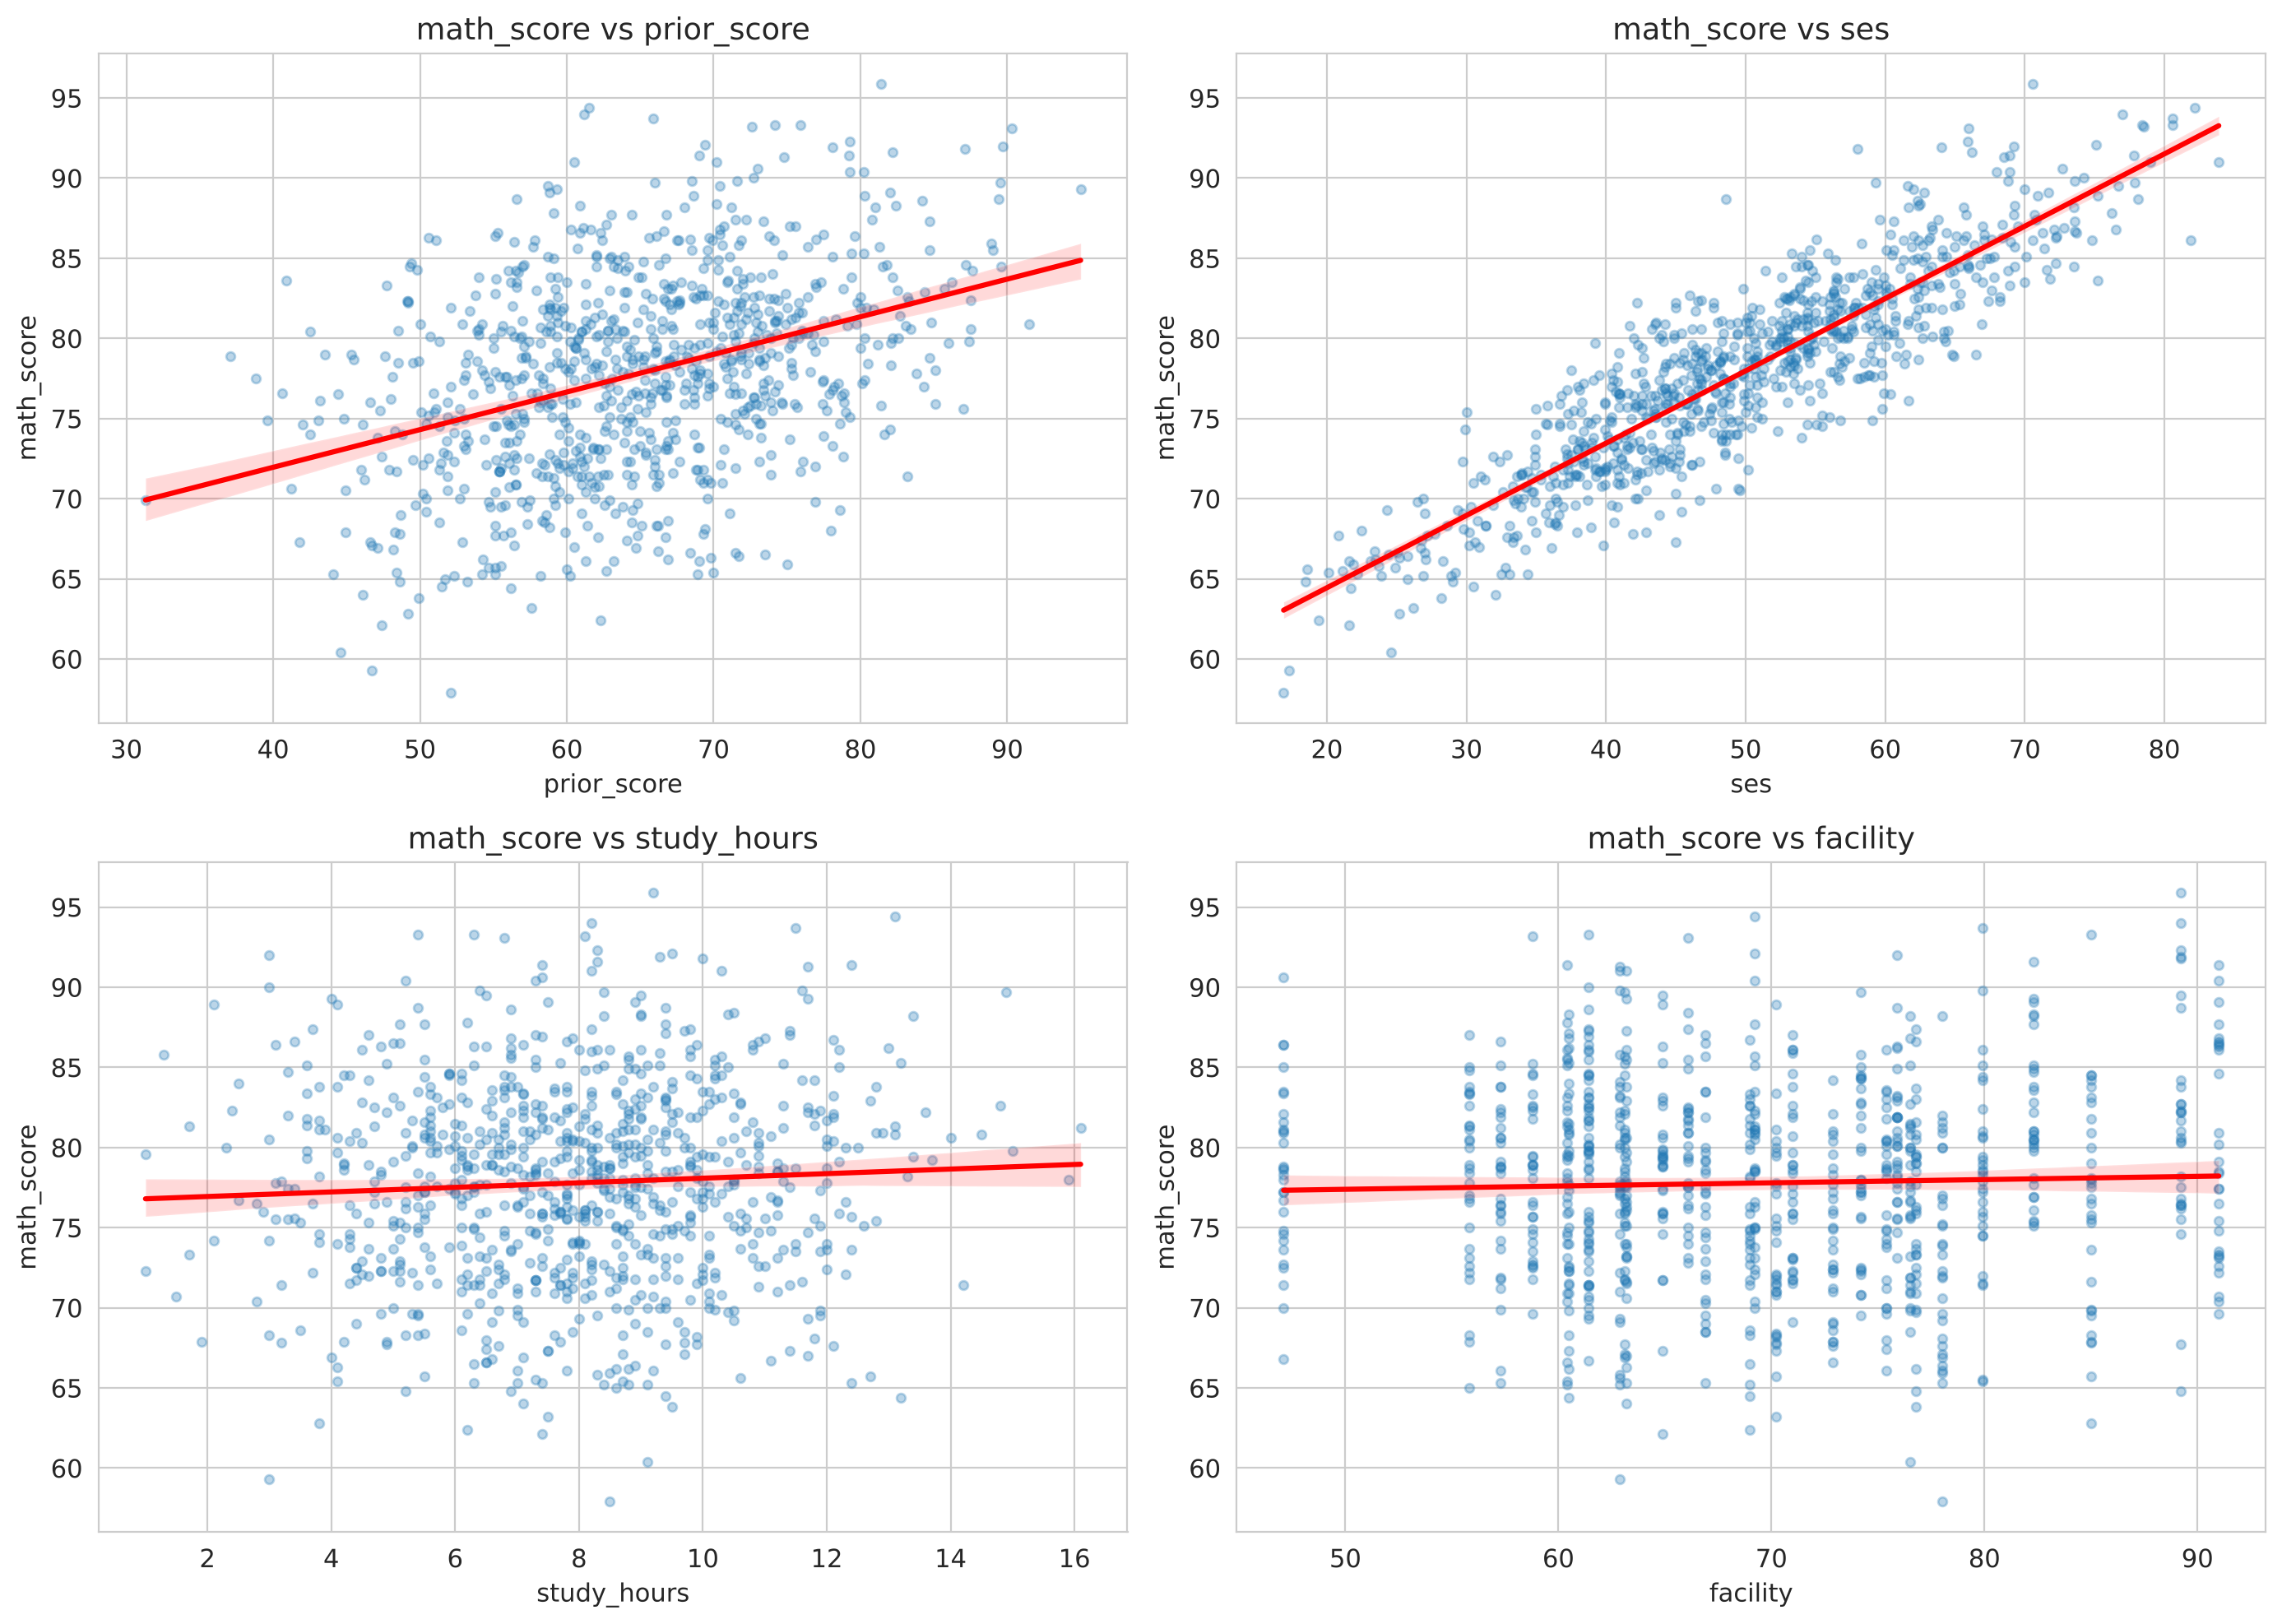

In [8]:
fig, axes = plt.subplots(2,2, figsize=(14,10))
for ax, v in zip(axes.flat, ['prior_score','ses','study_hours','facility']):
    sns.regplot(data=df, x=v, y='math_score', ax=ax,
                scatter_kws={'alpha':.3,'s':15}, line_kws={'color':'red'})
    ax.set_title(f'math_score vs {v}')
plt.tight_layout(); plt.show()

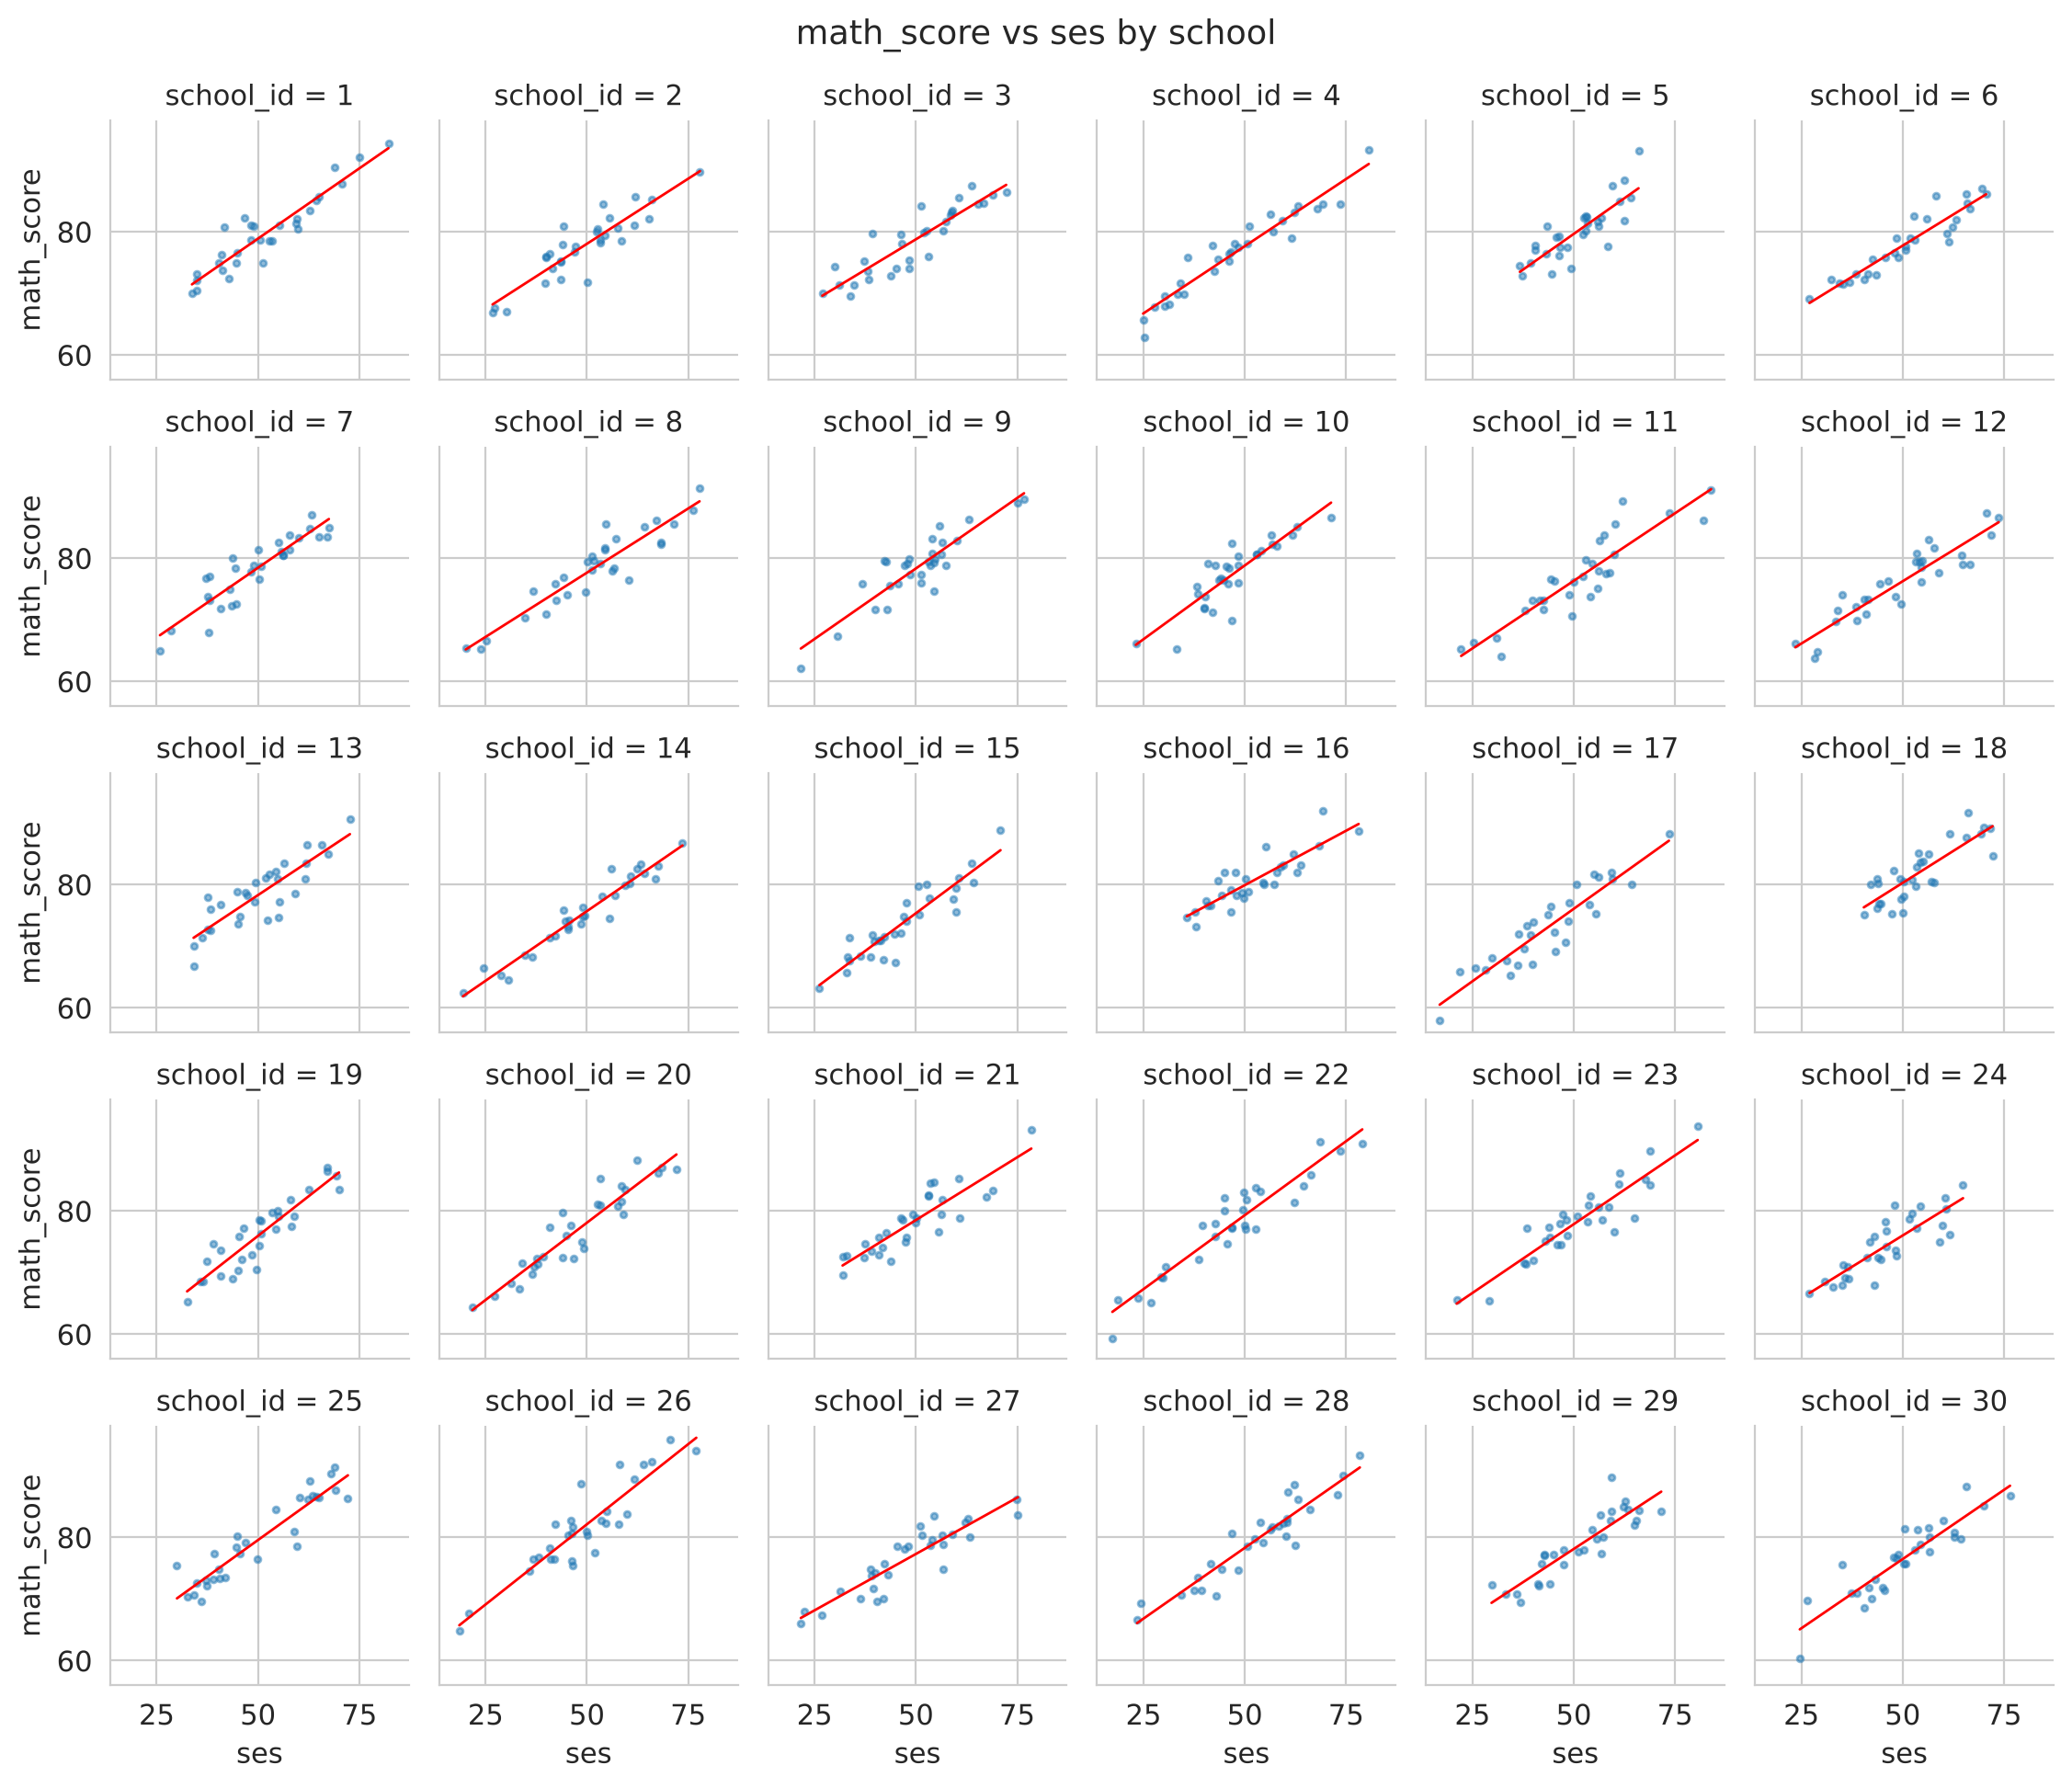

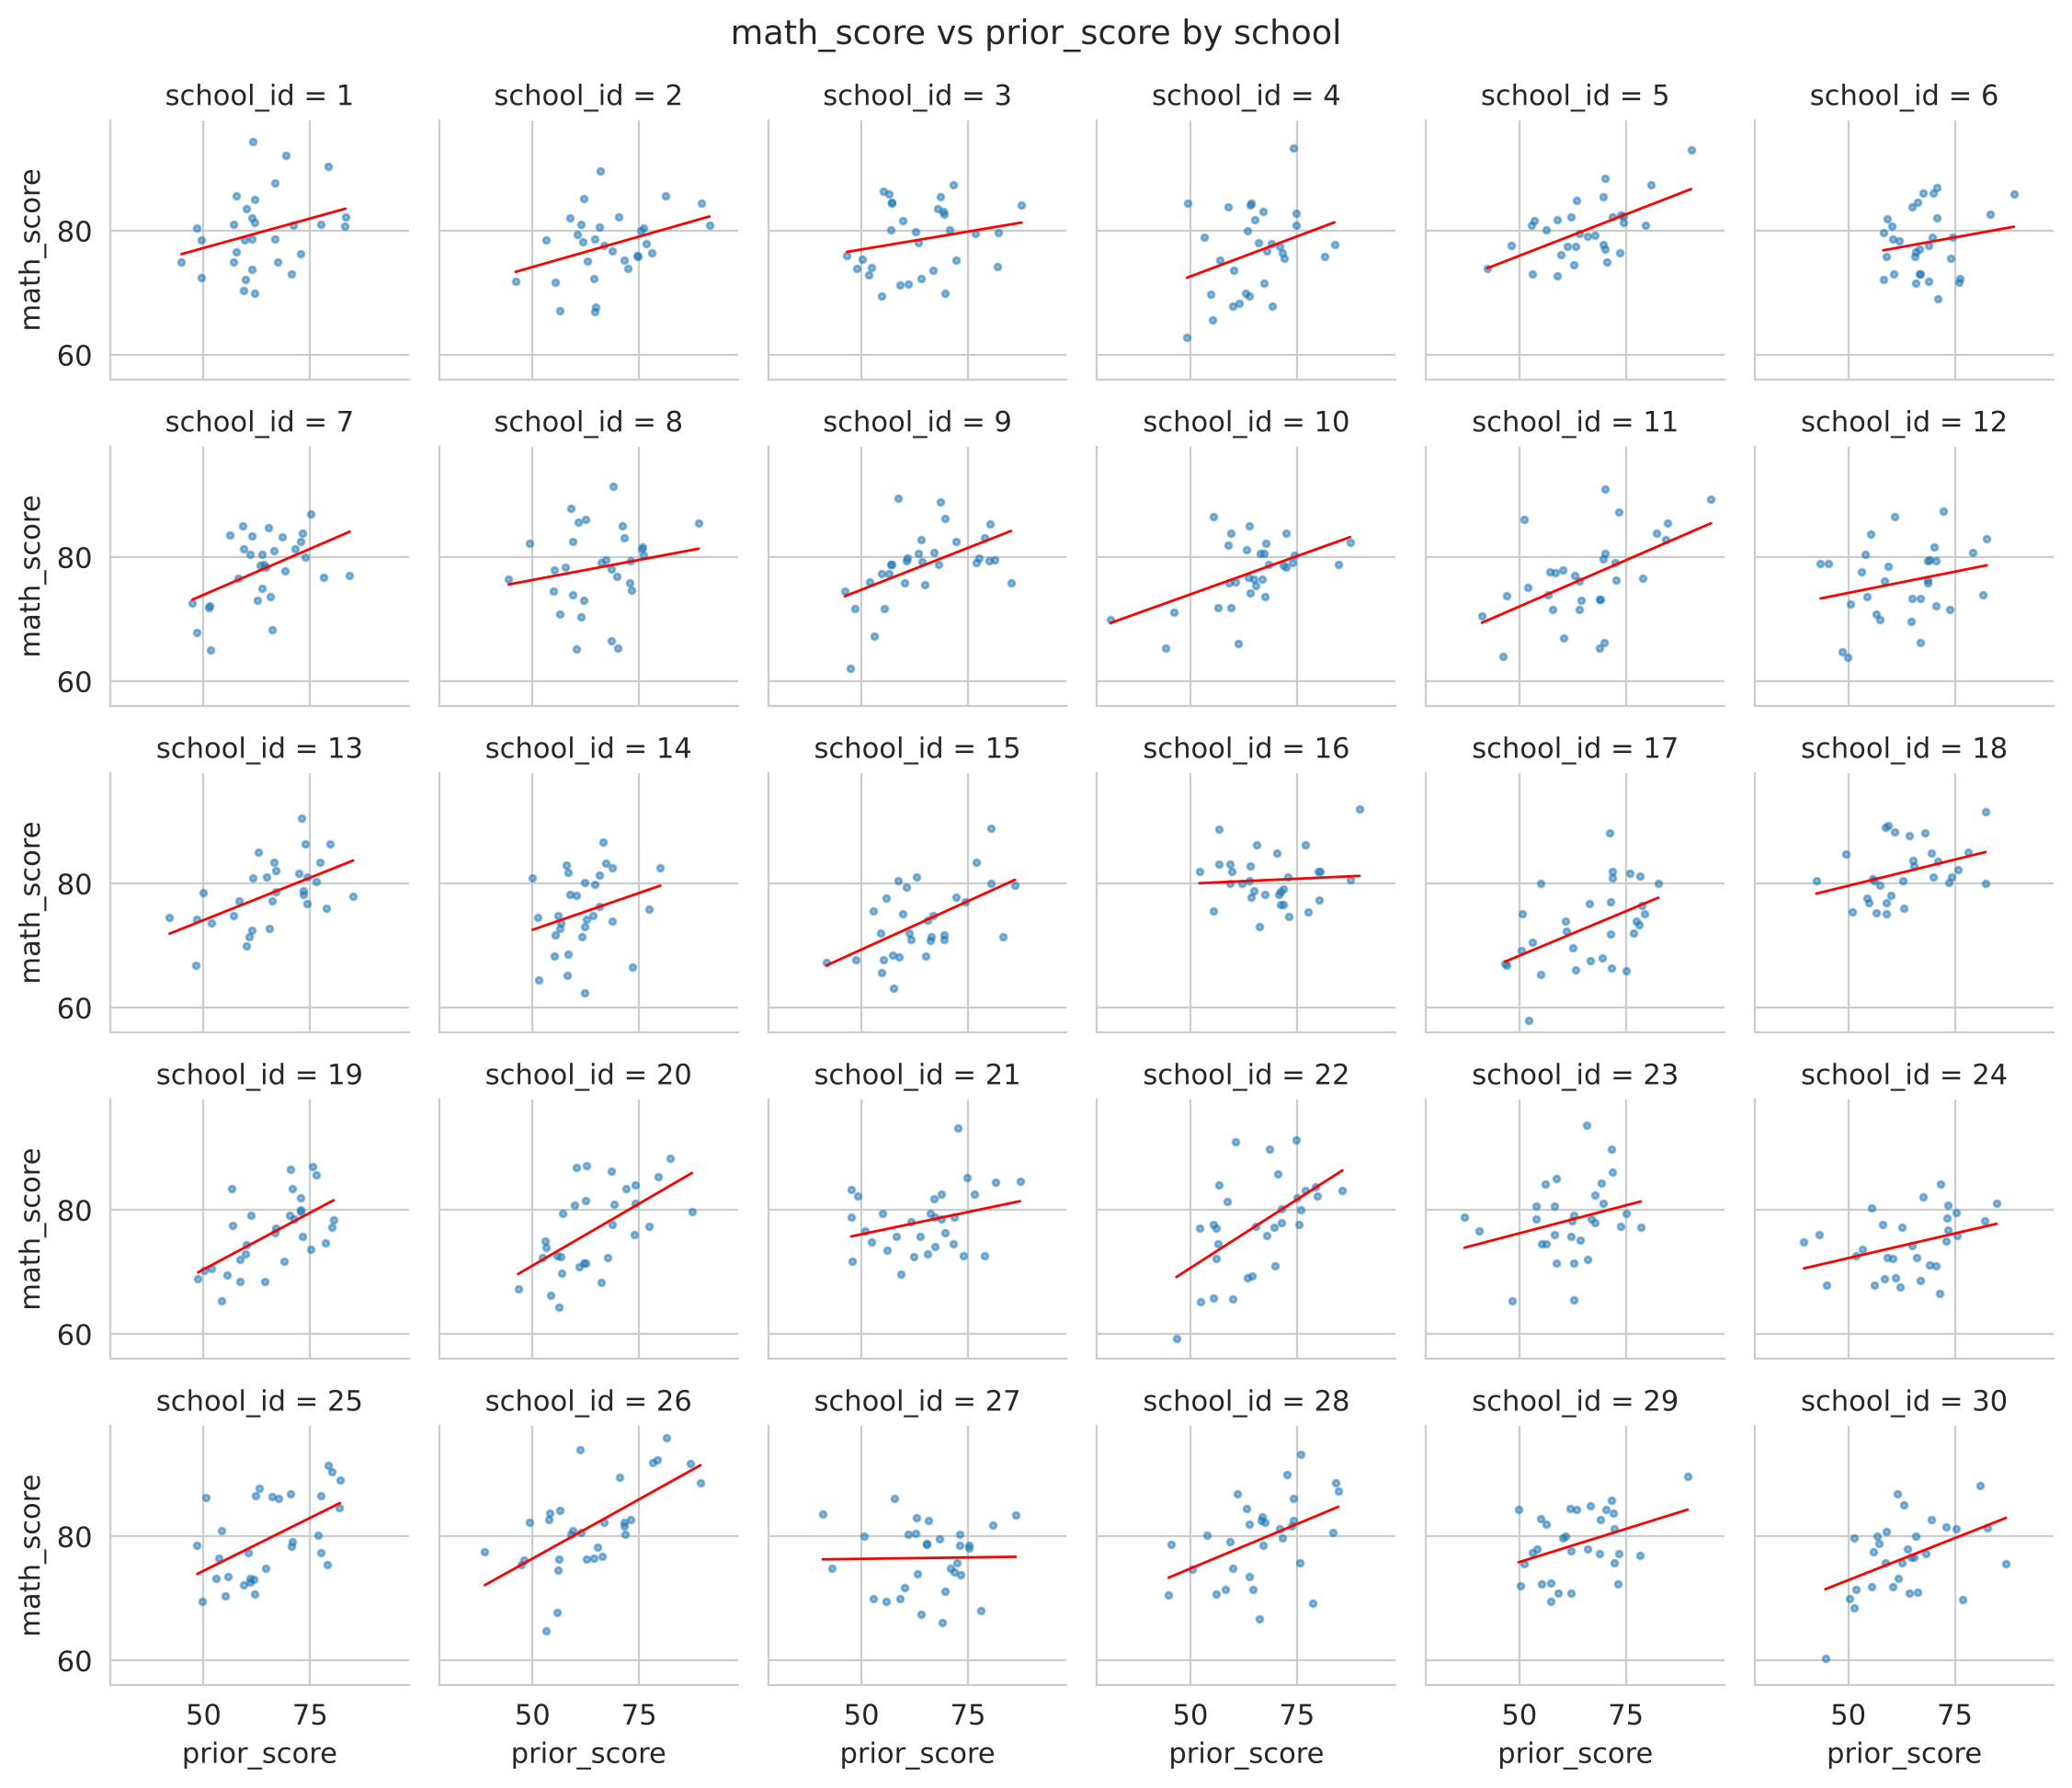

In [9]:
# 🆕 Per-school slopes (is the relationship with SES and prior score the same in every school?)
for v in ['ses','prior_score']:
    g = sns.lmplot(data=df, x=v, y='math_score', col='school_id', col_wrap=6,
                   height=1.9, aspect=1, ci=None, scatter_kws={'s':6,'alpha':.5},
                   line_kws={'color':'red','lw':1})
    g.fig.suptitle(f'math_score vs {v} by school', y=1.02)
    plt.show()

**Interpretation.** The per-school regression lines are almost parallel for SES and prior score. This supports a **random intercept** for these predictors (schools differ in baseline score, not in slope). This is tested formally in section 3.

In [10]:
grand_mean = df['math_score'].mean()
school_means = df.groupby('school_id', observed=True)['math_score'].transform('mean')
SS_between = ((school_means - grand_mean)**2).sum()
SS_within  = ((df['math_score'] - school_means)**2).sum()
print(f"SS Between-school : {SS_between:,.1f}  ({100*SS_between/(SS_between+SS_within):.2f}%)")
print(f"SS Within-school  : {SS_within:,.1f}  ({100*SS_within/(SS_between+SS_within):.2f}%)")

SS Between-school : 3,780.8  (10.93%)
SS Within-school  : 30,804.7  (89.07%)


## 3. Multilevel Models

In [11]:
print("="*65); print("3. MULTILEVEL MODELS"); print("="*65)

def fit_model(formula, data=df, reml=True):
    m = smf.mixedlm(formula, data, groups=data['school_id'])
    return m.fit(reml=reml)

f1 = "math_score ~ 1"
f2 = "math_score ~ prior_score_z + ses_z + study_hours_z + gender_male"
f3 = f2 + " + facility_z + teacher_exp_z"

# --- Model 1: NULL ---
m1 = fit_model(f1)
print("\n--- MODEL 1 (Null) ---")
print(m1.summary())

tau00_null  = float(m1.cov_re.iloc[0,0])
sigma2_null = float(m1.scale)
icc_null    = tau00_null / (tau00_null + sigma2_null)
deff        = 1 + (30-1)*icc_null
print(f"\n>>> Between-school variance (τ00) = {tau00_null:.3f}")
print(f">>> Within-school variance  (σ²)  = {sigma2_null:.3f}")
print(f">>> ICC = {icc_null:.4f}  ({icc_null*100:.2f}% of the variance lies at the school level)")
print(f">>> Design effect = {deff:.2f}  (OLS understates the variance by about {deff:.1f}x)")

3. MULTILEVEL MODELS

--- MODEL 1 (Null) ---
         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: math_score
No. Observations: 900     Method:             REML      
No. Groups:       30      Scale:              35.4077   
Min. group size:  30      Log-Likelihood:     -2901.2617
Max. group size:  30      Converged:          Yes       
Mean group size:  30.0                                  
--------------------------------------------------------
             Coef.  Std.Err.    z    P>|z| [0.025 0.975]
--------------------------------------------------------
Intercept    77.787    0.381 204.379 0.000 77.041 78.533
Group Var     3.165    0.195                            


>>> Between-school variance (τ00) = 3.165
>>> Within-school variance  (σ²)  = 35.408
>>> ICC = 0.0821  (8.21% of the variance lies at the school level)
>>> Design effect = 3.38  (OLS understates the variance by about 3.4x)


In [12]:
m2 = fit_model(f2)
print("--- MODEL 2 (Student-level) ---")
print(m2.summary())
tau00_m2, sigma2_m2 = float(m2.cov_re.iloc[0,0]), float(m2.scale)
icc_m2 = tau00_m2/(tau00_m2+sigma2_m2)
print(f"\n>>> τ00={tau00_m2:.3f}, σ²={sigma2_m2:.3f}, residual ICC={icc_m2:.4f}")

--- MODEL 2 (Student-level) ---
          Mixed Linear Model Regression Results
Model:             MixedLM Dependent Variable: math_score
No. Observations:  900     Method:             REML      
No. Groups:        30      Scale:              0.5069    
Min. group size:   30      Log-Likelihood:     -1053.7644
Max. group size:   30      Converged:          Yes       
Mean group size:   30.0                                  
---------------------------------------------------------
              Coef.  Std.Err.    z    P>|z| [0.025 0.975]
---------------------------------------------------------
Intercept     77.588    0.281 275.925 0.000 77.037 78.139
prior_score_z  2.345    0.024  97.400 0.000  2.298  2.392
ses_z          5.382    0.024 222.933 0.000  5.335  5.430
study_hours_z  0.333    0.024  13.825 0.000  0.286  0.380
gender_male    0.421    0.048   8.724 0.000  0.327  0.516
Group Var      2.340    0.884                            


>>> τ00=2.340, σ²=0.507, residual ICC=0.8219


In [13]:
m3 = fit_model(f3)
print("--- MODEL 3 (Full: student + school) ---")
print(m3.summary())
tau00_m3, sigma2_m3 = float(m3.cov_re.iloc[0,0]), float(m3.scale)
icc_m3 = tau00_m3/(tau00_m3+sigma2_m3)
print(f"\n>>> τ00={tau00_m3:.3f}, σ²={sigma2_m3:.3f}, residual ICC={icc_m3:.4f}")

--- MODEL 3 (Full: student + school) ---
          Mixed Linear Model Regression Results
Model:             MixedLM Dependent Variable: math_score
No. Observations:  900     Method:             REML      
No. Groups:        30      Scale:              0.5069    
Min. group size:   30      Log-Likelihood:     -1051.0055
Max. group size:   30      Converged:          Yes       
Mean group size:   30.0                                  
---------------------------------------------------------
              Coef.  Std.Err.    z    P>|z| [0.025 0.975]
---------------------------------------------------------
Intercept     77.588    0.258 301.256 0.000 77.083 78.093
prior_score_z  2.345    0.024  97.404 0.000  2.298  2.392
ses_z          5.382    0.024 222.936 0.000  5.335  5.430
study_hours_z  0.332    0.024  13.814 0.000  0.285  0.380
gender_male    0.422    0.048   8.729 0.000  0.327  0.516
facility_z     0.478    0.274   1.745 0.081 -0.059  1.015
teacher_exp_z  0.702    0.274   2.564 0.0

**Interpretation.** Coefficients in M2 and M3 are read as the change in mathematics score per 1 SD increase in a predictor (gender: male vs female), holding the other predictors and the school constant. Note that the **residual ICC** in M2/M3 jumps not because schools become more important, but because σ² drops sharply (most between-student variance is explained by the predictors). Q1 uses the **ICC of the null model**.

In [14]:
# 🆕 Random-slope tests: do the effects of student predictors differ across schools?
rs_rows = []
m3_ml = fit_model(f3, reml=False)
for v in ['ses_z','prior_score_z','study_hours_z']:
    try:
        ms = smf.mixedlm(f3, df, groups=df['school_id'], re_formula=f'~{v}').fit(reml=False)
        lrt = max(0.0, 2*(ms.llf - m3_ml.llf))
        p = stats.chi2.sf(lrt, 2)        # conservative (df=2)
        rs_rows.append([v, ms.llf, lrt, p, float(ms.cov_re.iloc[1,1])])
    except Exception as e:
        rs_rows.append([v, np.nan, np.nan, np.nan, np.nan]); print("Failed:", v, e)
rs = pd.DataFrame(rs_rows, columns=['Random slope','LogLik (ML)','LRT','p-value','Slope variance'])
print(f"LogLik M3 random-intercept (ML): {m3_ml.llf:.3f}")
print(rs.round(4).to_string(index=False))

LogLik M3 random-intercept (ML): -1039.146
 Random slope  LogLik (ML)     LRT  p-value  Slope variance
        ses_z   -1,039.130   0.031    0.985           0.001
prior_score_z   -1,039.512   0.000    1.000           0.001
study_hours_z     -906.250 265.791    0.000           0.141


**Interpretation.** The random slopes for `ses_z` and `prior_score_z` are **not significant** (slope variance ≈ 0), so the effects of SES and prior ability can be treated as equal across schools. In contrast, the random slope for `study_hours_z` is **highly significant**: the effect of study time differs across schools (per-school slopes range from negative to positive, see section 3b). The random-intercept model (M3) is therefore under-specified, and model M4 is added in the next section.

## 3b. Model M4: Random Slope for Study Hours (🆕)

In [15]:
# M4 = M3 + random slope for study_hours_z (the study-hours effect may differ across schools)
m_rs  = smf.mixedlm(f3, df, groups=df['school_id'], re_formula='~study_hours_z').fit(reml=True)
ml_rs = smf.mixedlm(f3, df, groups=df['school_id'], re_formula='~study_hours_z').fit(reml=False)
print("--- MODEL 4 (M3 + random slope for study_hours) ---")
print(m_rs.summary())

G = m_rs.cov_re.values
tau00_rs, tau11_rs, tau01_rs = float(G[0,0]), float(G[1,1]), float(G[0,1])
rho_rs, sigma2_rs = tau01_rs/np.sqrt(tau00_rs*tau11_rs), float(m_rs.scale)
lrt_rs = 2*(ml_rs.llf - fit_model(f3, reml=False).llf)
print(f"\n>>> τ00 (intercept variance) = {tau00_rs:.3f} | τ11 (study_hours slope variance) = {tau11_rs:.3f} | intercept-slope correlation ρ = {rho_rs:.2f}")
print(f">>> σ² = {sigma2_rs:.3f} (M3: {sigma2_m3:.3f})")
print(f">>> LRT M4 vs M3 (ML) = {lrt_rs:.1f}  → the random slope for study_hours is highly significant")
print(f">>> SD of slope across schools = {np.sqrt(tau11_rs):.3f}  vs mean slope = {m_rs.fe_params['study_hours_z']:.3f}")

--- MODEL 4 (M3 + random slope for study_hours) ---
                Mixed Linear Model Regression Results
Model:                 MixedLM     Dependent Variable:     math_score
No. Observations:      900         Method:                 REML      
No. Groups:            30          Scale:                  0.3648    
Min. group size:       30          Log-Likelihood:         -920.2396 
Max. group size:       30          Converged:              Yes       
Mean group size:       30.0                                          
---------------------------------------------------------------------
                          Coef.  Std.Err.    z    P>|z| [0.025 0.975]
---------------------------------------------------------------------
Intercept                 77.575    0.252 308.267 0.000 77.081 78.068
prior_score_z              2.341    0.021 113.672 0.000  2.301  2.382
ses_z                      5.376    0.021 259.656 0.000  5.335  5.416
study_hours_z              0.310    0.073   4.243 0.00

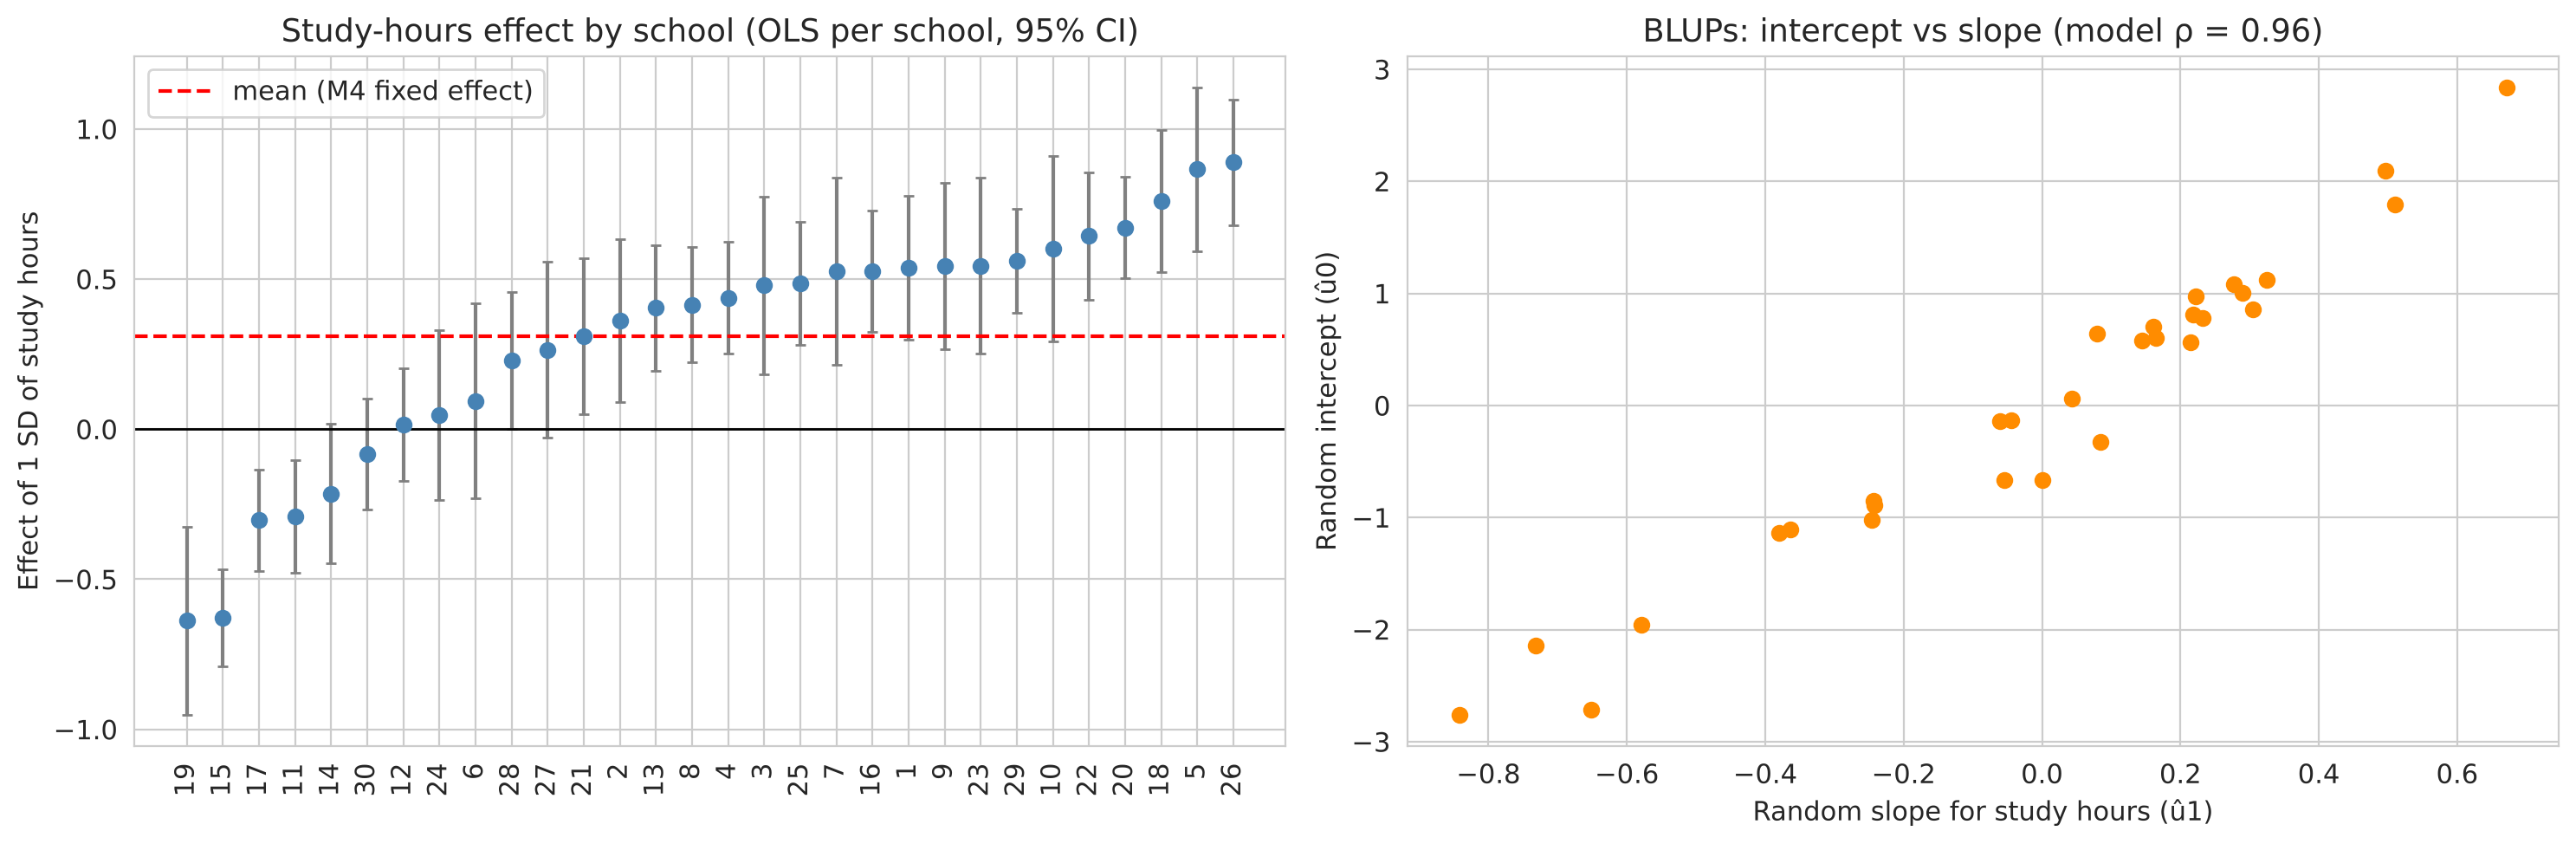

Levene, residual variance across schools (M4): p=0.348  (M3: p=<0.001)
Shapiro-Wilk residuals M4: W=0.9967, p=0.054


In [16]:
# Visual: per-school study-hours slope (OLS per school) and the intercept-slope BLUP relationship
rows = []
for s_, g in df.groupby('school_id', observed=True):
    r = smf.ols('math_score ~ prior_score_z + ses_z + study_hours_z + gender_male', g).fit()
    rows.append([s_, r.params['study_hours_z'], r.bse['study_hours_z']])
sl = pd.DataFrame(rows, columns=['school_id','slope','se']).sort_values('slope').reset_index(drop=True)

re_rs = pd.DataFrame({k: v.values for k, v in m_rs.random_effects.items()}).T
re_rs.columns = ['u0','u1']

fig, axes = plt.subplots(1, 2, figsize=(15,5))
axes[0].errorbar(sl.index, sl['slope'], yerr=1.96*sl['se'], fmt='o', color='steelblue', ecolor='gray', capsize=2)
axes[0].axhline(0, color='black', lw=1); axes[0].axhline(m_rs.fe_params['study_hours_z'], color='red', ls='--', label='mean (M4 fixed effect)')
axes[0].set_xticks(sl.index); axes[0].set_xticklabels(sl['school_id'], rotation=90)
axes[0].set_ylabel('Effect of 1 SD of study hours'); axes[0].set_title('Study-hours effect by school (OLS per school, 95% CI)'); axes[0].legend()
axes[1].scatter(re_rs['u1'], re_rs['u0'], color='darkorange')
axes[1].set_xlabel('Random slope for study hours (û1)'); axes[1].set_ylabel('Random intercept (û0)')
axes[1].set_title(f'BLUPs: intercept vs slope (model ρ = {rho_rs:.2f})')
plt.tight_layout(); plt.show()

# Quick diagnostics for M4
res_rs = m_rs.resid
lev_rs = stats.levene(*[g.values for _, g in res_rs.groupby(df['school_id'], observed=True)])
sw_rs  = stats.shapiro(res_rs)
print(f"Levene, residual variance across schools (M4): p={fp(lev_rs.pvalue)}  (M3: p={fp(stats.levene(*[g.values for _, g in m3.resid.groupby(df['school_id'], observed=True)]).pvalue)})")
print(f"Shapiro-Wilk residuals M4: W={sw_rs.statistic:.4f}, p={fp(sw_rs.pvalue)}")

**Interpretation.** The effect of study time is not uniform: it is positive in some schools and close to zero or even negative in others, so the average slope in the ordinary model (M3) hides this heterogeneity. The random slope and random intercept are very highly correlated (ρ close to 1): schools with a higher baseline score also tend to benefit more from study time. This suggests an **unmeasured school-level factor** that influences both. Adding the random slope also fixes the homoscedasticity of residuals across schools (Levene test), which is rejected for M3.

## 4. Variance Decomposition and Model Comparison

In [17]:
# 🔧 AIC/BIC computed manually from ML fits (statsmodels gives no AIC/BIC for REML fits)
print("="*65); print("4. VARIANCE DECOMPOSITION & MODEL COMPARISON"); print("="*65)

def pve(new, old): return (old - new) / old * 100

ml1, ml2, ml3 = fit_model(f1, reml=False), fit_model(f2, reml=False), fit_model(f3, reml=False)
def ic(m, n=len(df)):
    q = m.cov_re.shape[0]
    k = len(m.fe_params) + q*(q+1)//2 + 1         # fixed + random-effect covariance parameters + σ²
    return -2*m.llf + 2*k, -2*m.llf + np.log(n)*k
aic = [ic(m)[0] for m in (ml1, ml2, ml3, ml_rs)]
bic = [ic(m)[1] for m in (ml1, ml2, ml3, ml_rs)]
total_null = tau00_null + sigma2_null

summary_tbl = pd.DataFrame({
    'Model'            : ['M1 Null','M2 Student','M3 Full','M4 M3+slope study'],
    'τ00 (school)'     : [tau00_null, tau00_m2, tau00_m3, tau00_rs],
    'σ² (student)'     : [sigma2_null, sigma2_m2, sigma2_m3, sigma2_rs],
    'Residual ICC'     : [icc_null, icc_m2, icc_m3, np.nan],
    'τ00 / total null (%)': [100*t/total_null for t in (tau00_null, tau00_m2, tau00_m3, tau00_rs)],
    'AIC (ML)'         : aic,
    'BIC (ML)'         : bic,
    'LogLik (ML)'      : [ml1.llf, ml2.llf, ml3.llf, ml_rs.llf],
})
print(summary_tbl.round(3).to_string(index=False))
print("\nNote: 'Residual ICC' in M2/M3 is NOT a measure of how important schools are (it rises because σ² falls).")
print("      The comparable measure across models is 'τ00 / total null'.")

print(f"\n>>> PVE school-level variance M1→M2 (student predictors): {pve(tau00_m2, tau00_null):.2f}%")
print(f">>> PVE school-level variance M2→M3 (school predictors) : {pve(tau00_m3, tau00_m2):.2f}%")
print(f">>> PVE school-level variance M1→M3 (total)             : {pve(tau00_m3, tau00_null):.2f}%")
print(f">>> PVE within-school variance M1→M3                    : {pve(sigma2_m3, sigma2_null):.2f}%")

4. VARIANCE DECOMPOSITION & MODEL COMPARISON
            Model  τ00 (school)  σ² (student)  Residual ICC  τ00 / total null (%)  AIC (ML)  BIC (ML)  LogLik (ML)
          M1 Null         3.165        35.408         0.082                 8.206 5,808.412 5,822.819   -2,901.206
       M2 Student         2.340         0.507         0.822                 6.065 2,099.730 2,133.347   -1,042.865
          M3 Full         1.957         0.507         0.794                 5.075 2,096.291 2,139.513   -1,039.146
M4 M3+slope study         1.876         0.365           NaN                 4.864 1,834.500 1,887.326     -906.250

Note: 'Residual ICC' in M2/M3 is NOT a measure of how important schools are (it rises because σ² falls).
      The comparable measure across models is 'τ00 / total null'.

>>> PVE school-level variance M1→M2 (student predictors): 26.09%
>>> PVE school-level variance M2→M3 (school predictors) : 16.33%
>>> PVE school-level variance M1→M3 (total)             : 38.16%
>>> PVE with

In [18]:
def nakagawa_r2(model):
    X = model.model.exog
    beta = model.fe_params.values
    var_fixed  = np.var(X @ beta)
    var_random = float(model.cov_re.iloc[0,0])
    var_resid  = float(model.scale)
    tot = var_fixed + var_random + var_resid
    return var_fixed/tot, (var_fixed + var_random)/tot

r2 = {}
for name, m in [('M1', m1), ('M2', m2), ('M3', m3)]:
    r2[name] = nakagawa_r2(m)
    print(f"{name}: R²marginal={r2[name][0]:.4f}  R²conditional={r2[name][1]:.4f}")

M1: R²marginal=0.0000  R²conditional=0.0821
M2: R²marginal=0.9245  R²conditional=0.9866
M3: R²marginal=0.9349  R²conditional=0.9866


**Interpretation.** Student predictors explain almost all of the within-school variation (σ² falls by more than 98%). School predictors explain additional between-school variation beyond what student composition explains. M3 has lower AIC/BIC than M2, so school variables improve model fit. **M4 (random slope for study_hours) has much lower AIC/BIC than M3**, so M4 is the specification that best matches the data. (For M4 the 'residual ICC' is not defined because the between-school variance depends on the value of study hours; τ00 in M4 is the intercept variance at average study hours.)

## 5. Formal Tests: Q1, Q3 (joint), and Q4

In [19]:
# 🔧 All LRTs use ML for both models (apples to apples)
print("="*65); print("5. LIKELIHOOD RATIO TESTS"); print("="*65)

# (a) Q1: is there between-school variation in the null model? (mixed vs intercept-only OLS)
ols0 = smf.ols(f1, df).fit()
lrt_q1 = 2*(ml1.llf - ols0.llf); p_q1 = 0.5*stats.chi2.sf(lrt_q1, 1)
print(f"[Q1] M1 null vs OLS : LRT = {lrt_q1:.2f}, p = {fp(p_q1)}  → H0: τ00 = 0 {'rejected' if p_q1<.05 else 'not rejected'}")

# (b) Q3 joint: do facility + teacher_exp jointly improve the model? (M2 vs M3, df=2)
lrt_q3 = 2*(ml3.llf - ml2.llf); p_q3 = stats.chi2.sf(lrt_q3, 2)
print(f"[Q3] M2 vs M3 (2 df): LRT = {lrt_q3:.2f}, p = {fp(p_q3)}  → school variables jointly {'significant' if p_q3<.05 else 'not significant'}")

# (c) Q4: is the residual τ00 in the full model still > 0?
ols3 = smf.ols(f3, df).fit()
lrt_q4 = 2*(ml3.llf - ols3.llf); p_q4 = 0.5*stats.chi2.sf(lrt_q4, 1)
se_tau3 = float(m3.bse_re['Group Var'])   # SE on the variance scale (same as the summary table)
print(f"[Q4] M3 vs OLS      : LRT = {lrt_q4:.2f}, p = {fp(p_q4)}  → H0: residual τ00 = 0 {'rejected' if p_q4<.05 else 'not rejected'}")
print(f"     residual τ00 (REML) = {tau00_m3:.3f}, SE = {se_tau3:.3f}, z = {tau00_m3/se_tau3:.2f} (Wald, indicative only)")
print(f"     Residual τ00 = {100*tau00_m3/tau00_null:.1f}% of the initial τ00, or {100*tau00_m3/total_null:.1f}% of the total null-model variance")

5. LIKELIHOOD RATIO TESTS
[Q1] M1 null vs OLS : LRT = 35.59, p = <0.001  → H0: τ00 = 0 rejected
[Q3] M2 vs M3 (2 df): LRT = 7.44, p = 0.024  → school variables jointly significant
[Q4] M3 vs OLS      : LRT = 1205.19, p = <0.001  → H0: residual τ00 = 0 rejected
     residual τ00 (REML) = 1.957, SE = 0.766, z = 2.56 (Wald, indicative only)
     Residual τ00 = 61.8% of the initial τ00, or 5.1% of the total null-model variance


**Interpretation.** (a) Between-school variation is real (Q1). (b) The joint test assesses whether `facility` and `teacher_exp` *together* add explanatory power. (c) If the Q4 test is significant, there are still between-school differences that the available variables do not explain, for example school culture, leadership, or other unmeasured factors.

## 5b. Robustness of School-Level Effects (🆕)

In [20]:
# Effects of facility & teacher_exp under several specifications
rob = []
for name, m in [('M3: random intercept (REML)', m3), ('M4: + random slope study_hours (REML)', m_rs)]:
    for v in ['facility_z','teacher_exp_z']:
        rob.append([name, v, m.fe_params[v], m.bse_fe[v], m.pvalues[v]])

ols_cl = smf.ols(f3, df).fit(cov_type='cluster', cov_kwds={'groups': df['school_id'].cat.codes})
for v in ['facility_z','teacher_exp_z']:
    rob.append(['OLS + school-clustered SE', v, ols_cl.params[v], ols_cl.bse[v], ols_cl.pvalues[v]])

# Two-stage: score adjusted for student effects -> school means -> OLS (30 points)
wfit = smf.ols('math_score ~ C(school_id) + prior_score_z + ses_z + study_hours_z + gender_male', df).fit()
bst = wfit.params[['prior_score_z','ses_z','study_hours_z','gender_male']]
df['adj'] = df['math_score'] - df[['prior_score_z','ses_z','study_hours_z','gender_male']] @ bst
s2 = df.groupby('school_id', observed=True).agg(adj=('adj','mean'), facility_z=('facility_z','first'), teacher_exp_z=('teacher_exp_z','first'))
ts = sm.OLS(s2['adj'], sm.add_constant(s2[['facility_z','teacher_exp_z']])).fit()
for v in ['facility_z','teacher_exp_z']:
    rob.append(['Two-stage (school-level regression, n=30)', v, ts.params[v], ts.bse[v], ts.pvalues[v]])

rob_df = pd.DataFrame(rob, columns=['Specification','Variable','Coefficient','SE','p-value'])
rob_df['Significant (5%)'] = np.where(rob_df['p-value']<0.05, 'Yes', 'No')
print(rob_df.round(4).to_string(index=False))
n_sig_fa = int(((rob_df['Variable']=='facility_z') & (rob_df['p-value']<.05)).sum())
n_sig_te = int(((rob_df['Variable']=='teacher_exp_z') & (rob_df['p-value']<.05)).sum())
print(f"\nteacher_exp is significant in {n_sig_te}/4 specifications; facility is significant in {n_sig_fa}/4 specifications.")

# Q4 under M4: is the random-effect block (intercept + slope) still > 0?
lrt_q4_rs = 2*(ml_rs.llf - ols3.llf)
p_q4_rs = 0.5*stats.chi2.sf(lrt_q4_rs, 2) + 0.5*stats.chi2.sf(lrt_q4_rs, 3)
se_tau_rs = float(m_rs.bse_re['Group Var'])
print(f"\n[Q4 under M4] LRT of random-effect block vs OLS = {lrt_q4_rs:.1f}, p = {fp(p_q4_rs)}; τ00 = {tau00_rs:.3f} (SE {se_tau_rs:.3f})")

                            Specification      Variable  Coefficient    SE  p-value Significant (5%)
              M3: random intercept (REML)    facility_z        0.478 0.274    0.081               No
              M3: random intercept (REML) teacher_exp_z        0.702 0.274    0.010              Yes
    M4: + random slope study_hours (REML)    facility_z        0.385 0.108    0.000              Yes
    M4: + random slope study_hours (REML) teacher_exp_z        0.457 0.112    0.000              Yes
                OLS + school-clustered SE    facility_z        0.477 0.285    0.094               No
                OLS + school-clustered SE teacher_exp_z        0.703 0.245    0.004              Yes
Two-stage (school-level regression, n=30)    facility_z        0.478 0.274    0.092               No
Two-stage (school-level regression, n=30) teacher_exp_z        0.702 0.274    0.016              Yes

teacher_exp is significant in 4/4 specifications; facility is significant in 1/4 specifica

**Interpretation.** The effect of `teacher_exp` is positive and significant in **all** specifications, so this finding is robust. The significance of `facility` **depends on the specification**: it is not significant under the random-intercept model, clustered SEs, and the school-level regression, but it is significant under M4. In M4 the standard errors of school-level effects shrink because the model exploits the very high intercept-slope correlation (ρ ≈ 1), estimated from only 30 schools. The `facility` effect should therefore be reported as **indicative (positive direction, evidence not yet consistent)**, not as a firm conclusion.

## 6. Assumption Diagnostics for Model M3 (🆕)

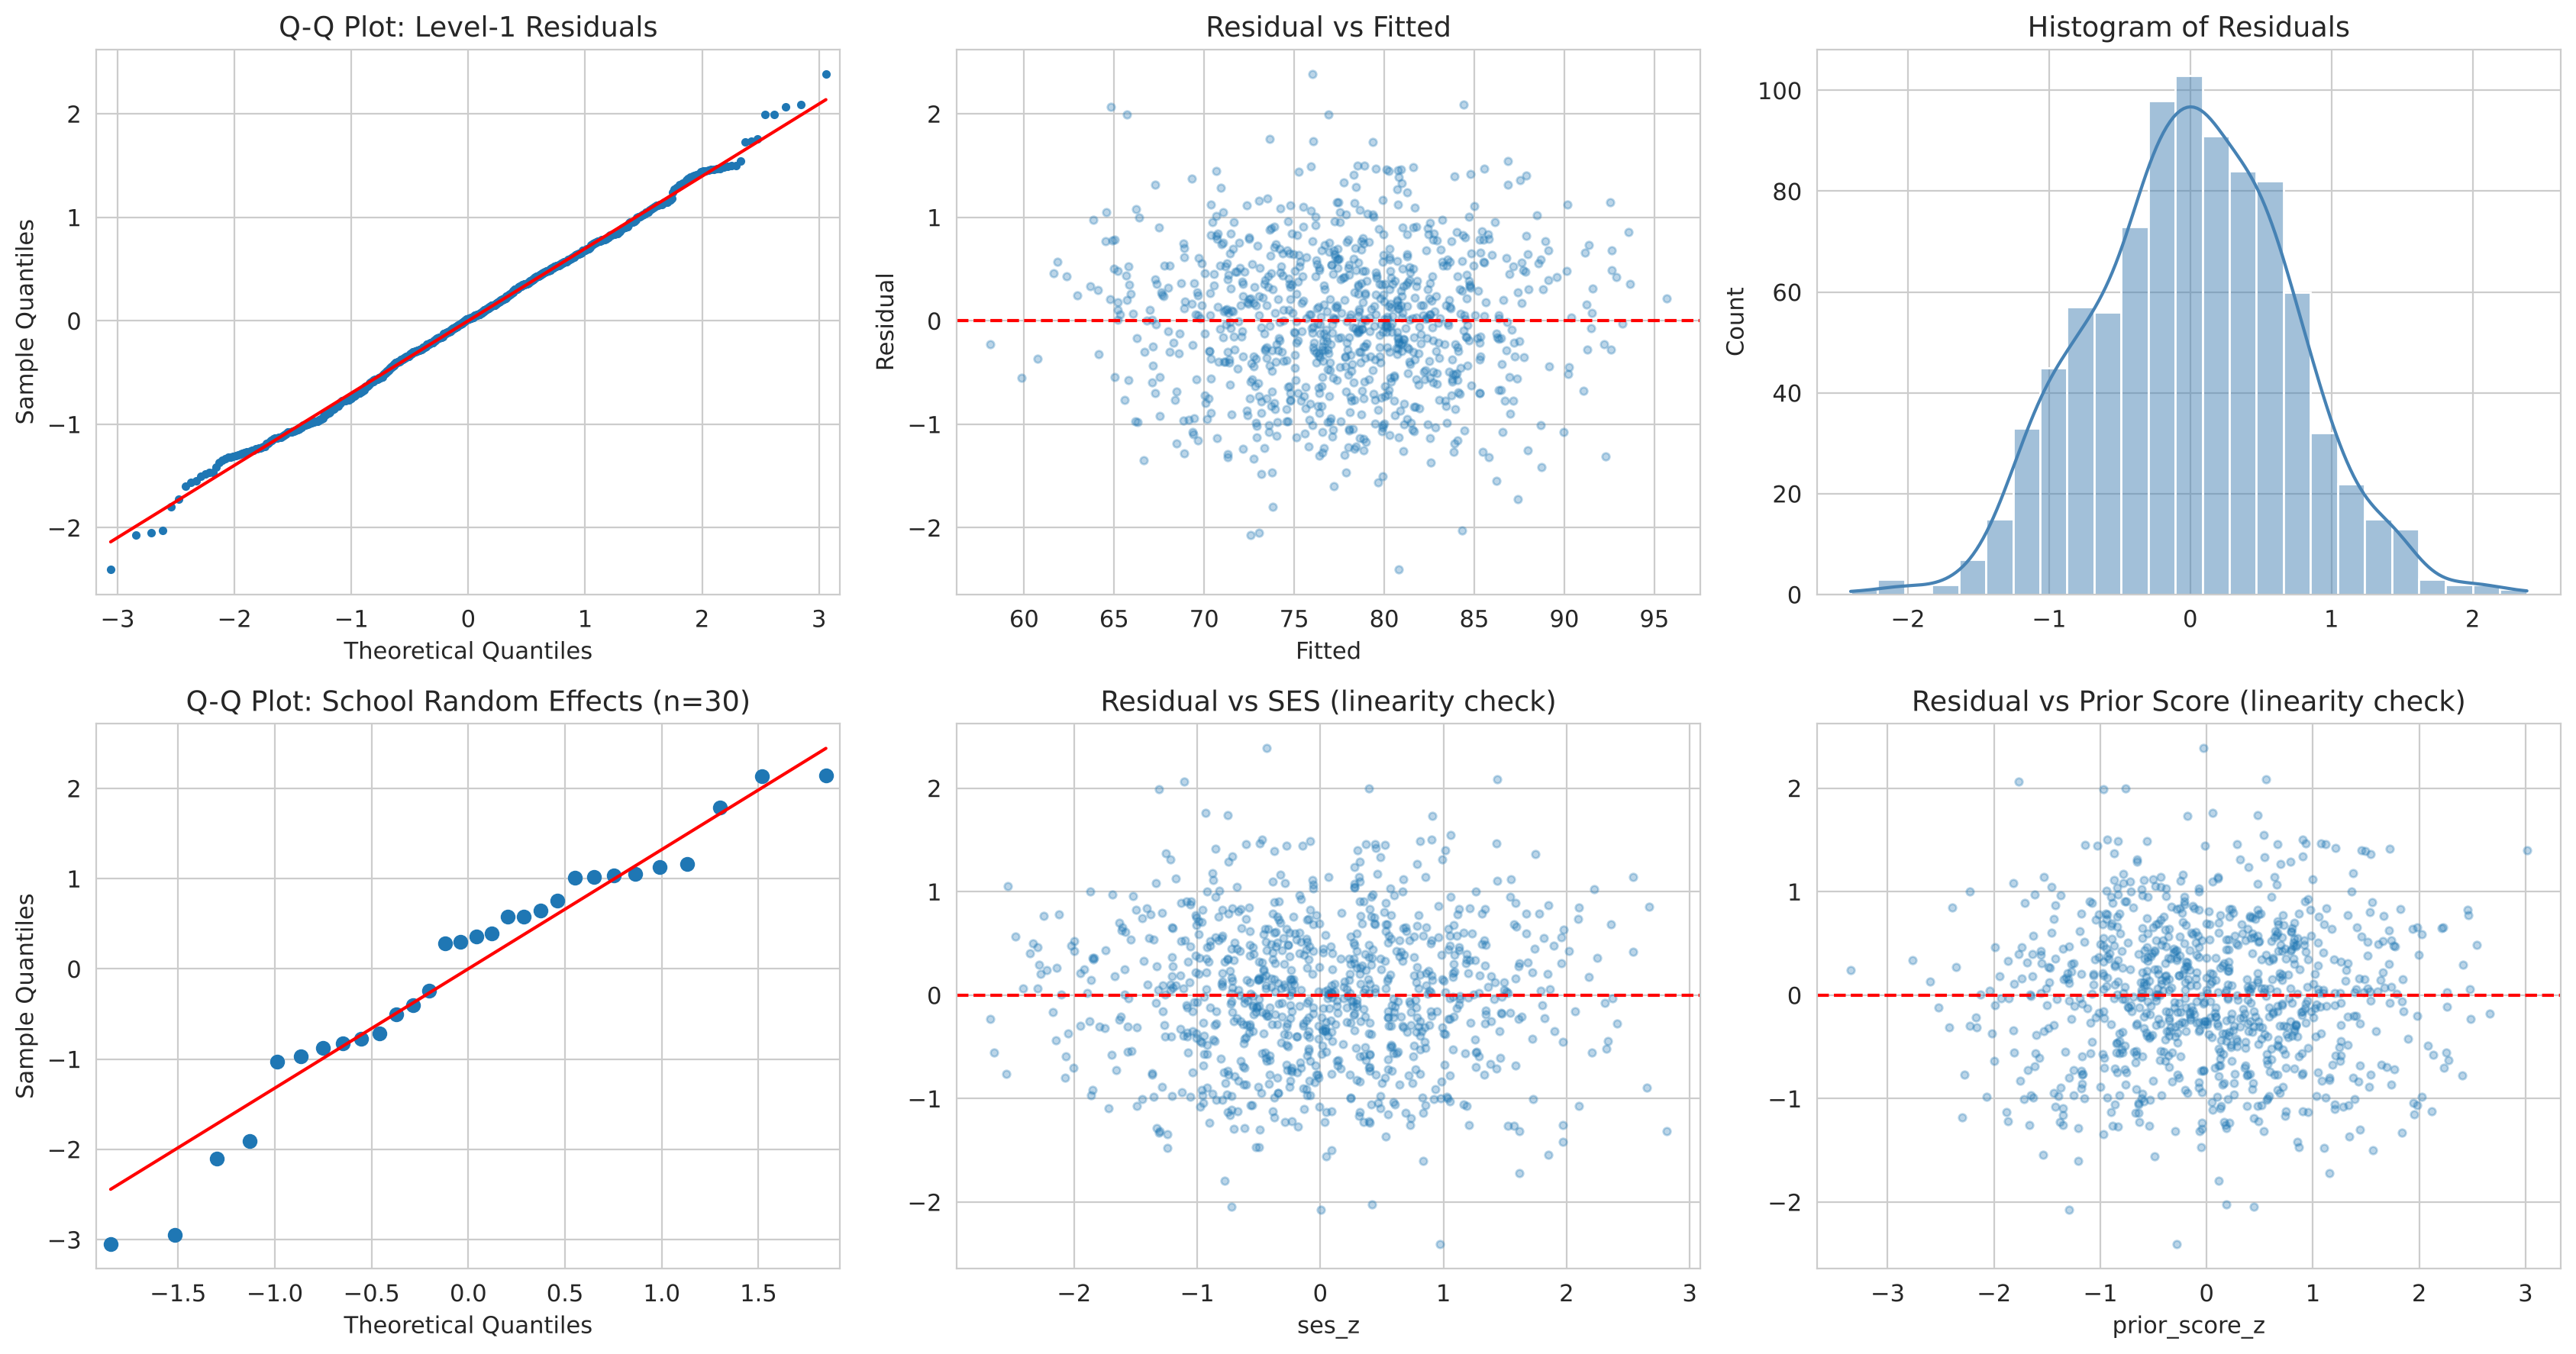

Shapiro-Wilk, level-1 residuals : W=0.9982, p=0.454 | skew=0.006, excess kurtosis=0.015
Shapiro-Wilk, random effects    : W=0.9488, p=0.157
Levene (residual variance across schools): stat=2.564, p=<0.001


In [21]:
resid = m3.resid                                   # conditional residuals (y - Xb - u_j)
u = pd.Series({k: float(v.iloc[0]) for k, v in m3.random_effects.items()}).sort_values()
fitted_cond = m3.fittedvalues

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
sm.qqplot(resid, line='s', ax=axes[0,0], markersize=3); axes[0,0].set_title('Q-Q Plot: Level-1 Residuals')
axes[0,1].scatter(fitted_cond, resid, alpha=.3, s=12); axes[0,1].axhline(0, color='red', ls='--')
axes[0,1].set_xlabel('Fitted'); axes[0,1].set_ylabel('Residual'); axes[0,1].set_title('Residual vs Fitted')
sns.histplot(resid, kde=True, ax=axes[0,2], color='steelblue'); axes[0,2].set_title('Histogram of Residuals')
sm.qqplot(u.values, line='s', ax=axes[1,0]); axes[1,0].set_title('Q-Q Plot: School Random Effects (n=30)')
axes[1,1].scatter(df['ses_z'], resid, alpha=.3, s=12); axes[1,1].axhline(0, color='red', ls='--')
axes[1,1].set_xlabel('ses_z'); axes[1,1].set_title('Residual vs SES (linearity check)')
axes[1,2].scatter(df['prior_score_z'], resid, alpha=.3, s=12); axes[1,2].axhline(0, color='red', ls='--')
axes[1,2].set_xlabel('prior_score_z'); axes[1,2].set_title('Residual vs Prior Score (linearity check)')
plt.tight_layout(); plt.show()

sw_r = stats.shapiro(resid); sw_u = stats.shapiro(u.values)
print(f"Shapiro-Wilk, level-1 residuals : W={sw_r.statistic:.4f}, p={fp(sw_r.pvalue)} | skew={stats.skew(resid):.3f}, excess kurtosis={stats.kurtosis(resid):.3f}")
print(f"Shapiro-Wilk, random effects    : W={sw_u.statistic:.4f}, p={fp(sw_u.pvalue)}")

# Homoscedasticity across schools (Levene on residuals)
groups_res = [g.values for _, g in resid.groupby(df['school_id'], observed=True)]
lev = stats.levene(*groups_res)
print(f"Levene (residual variance across schools): stat={lev.statistic:.3f}, p={fp(lev.pvalue)}")

**Interpretation.** The Q-Q points for residuals and random effects follow the diagonal, and the Shapiro-Wilk p-values are above 0.05, so **normality** is not rejected. The residual-vs-predictor plots show no curvature, so **linearity** holds. However, the **Levene test rejects homogeneity of residual variance across schools** for M3, which is consistent with the finding that the effect of study hours differs across schools (random slope, section 3b). The problem is resolved in M4. For the random effects, normality is only indicative because n = 30.

In [22]:
# School influence: leave-one-school-out (LOSO) for the school-level effects
rows = []
for s in df['school_id'].cat.categories:
    d = df[df['school_id'] != s].copy()
    mm = smf.mixedlm(f3, d, groups=d['school_id'].astype(str)).fit(reml=True)
    rows.append([s, mm.fe_params['facility_z'], mm.pvalues['facility_z'],
                 mm.fe_params['teacher_exp_z'], mm.pvalues['teacher_exp_z']])
loso = pd.DataFrame(rows, columns=['School dropped','coef_facility','p_facility','coef_teacher','p_teacher'])
print("=== Leave-one-school-out ===")
print(loso[['coef_facility','p_facility','coef_teacher','p_teacher']].describe().loc[['min','mean','max']].round(4))
print(f"\nSchool with the largest |u0j|: {u.abs().idxmax()} (u0j = {u[u.abs().idxmax()]:.3f})")
print(f"teacher_exp stays p<0.05 in {(loso['p_teacher']<0.05).sum()}/30 scenarios; facility p<0.05 in {(loso['p_facility']<0.05).sum()}/30 scenarios")

=== Leave-one-school-out ===
      coef_facility  p_facility  coef_teacher  p_teacher
min           0.150       0.022         0.382      0.003
mean          0.474       0.103         0.699      0.018
max           0.586       0.621         0.768      0.206

School with the largest |u0j|: 17 (u0j = -3.050)
teacher_exp stays p<0.05 in 29/30 scenarios; facility p<0.05 in 2/30 scenarios


**Interpretation.** With only 30 school-level units, a single school can influence the `facility` and `teacher_exp` effects. The range of coefficients and p-values when each school is dropped shows **how stable** the Q3 conclusions are. The more scenarios that remain significant, the more solid the finding.

## 7. Visualizing the Results

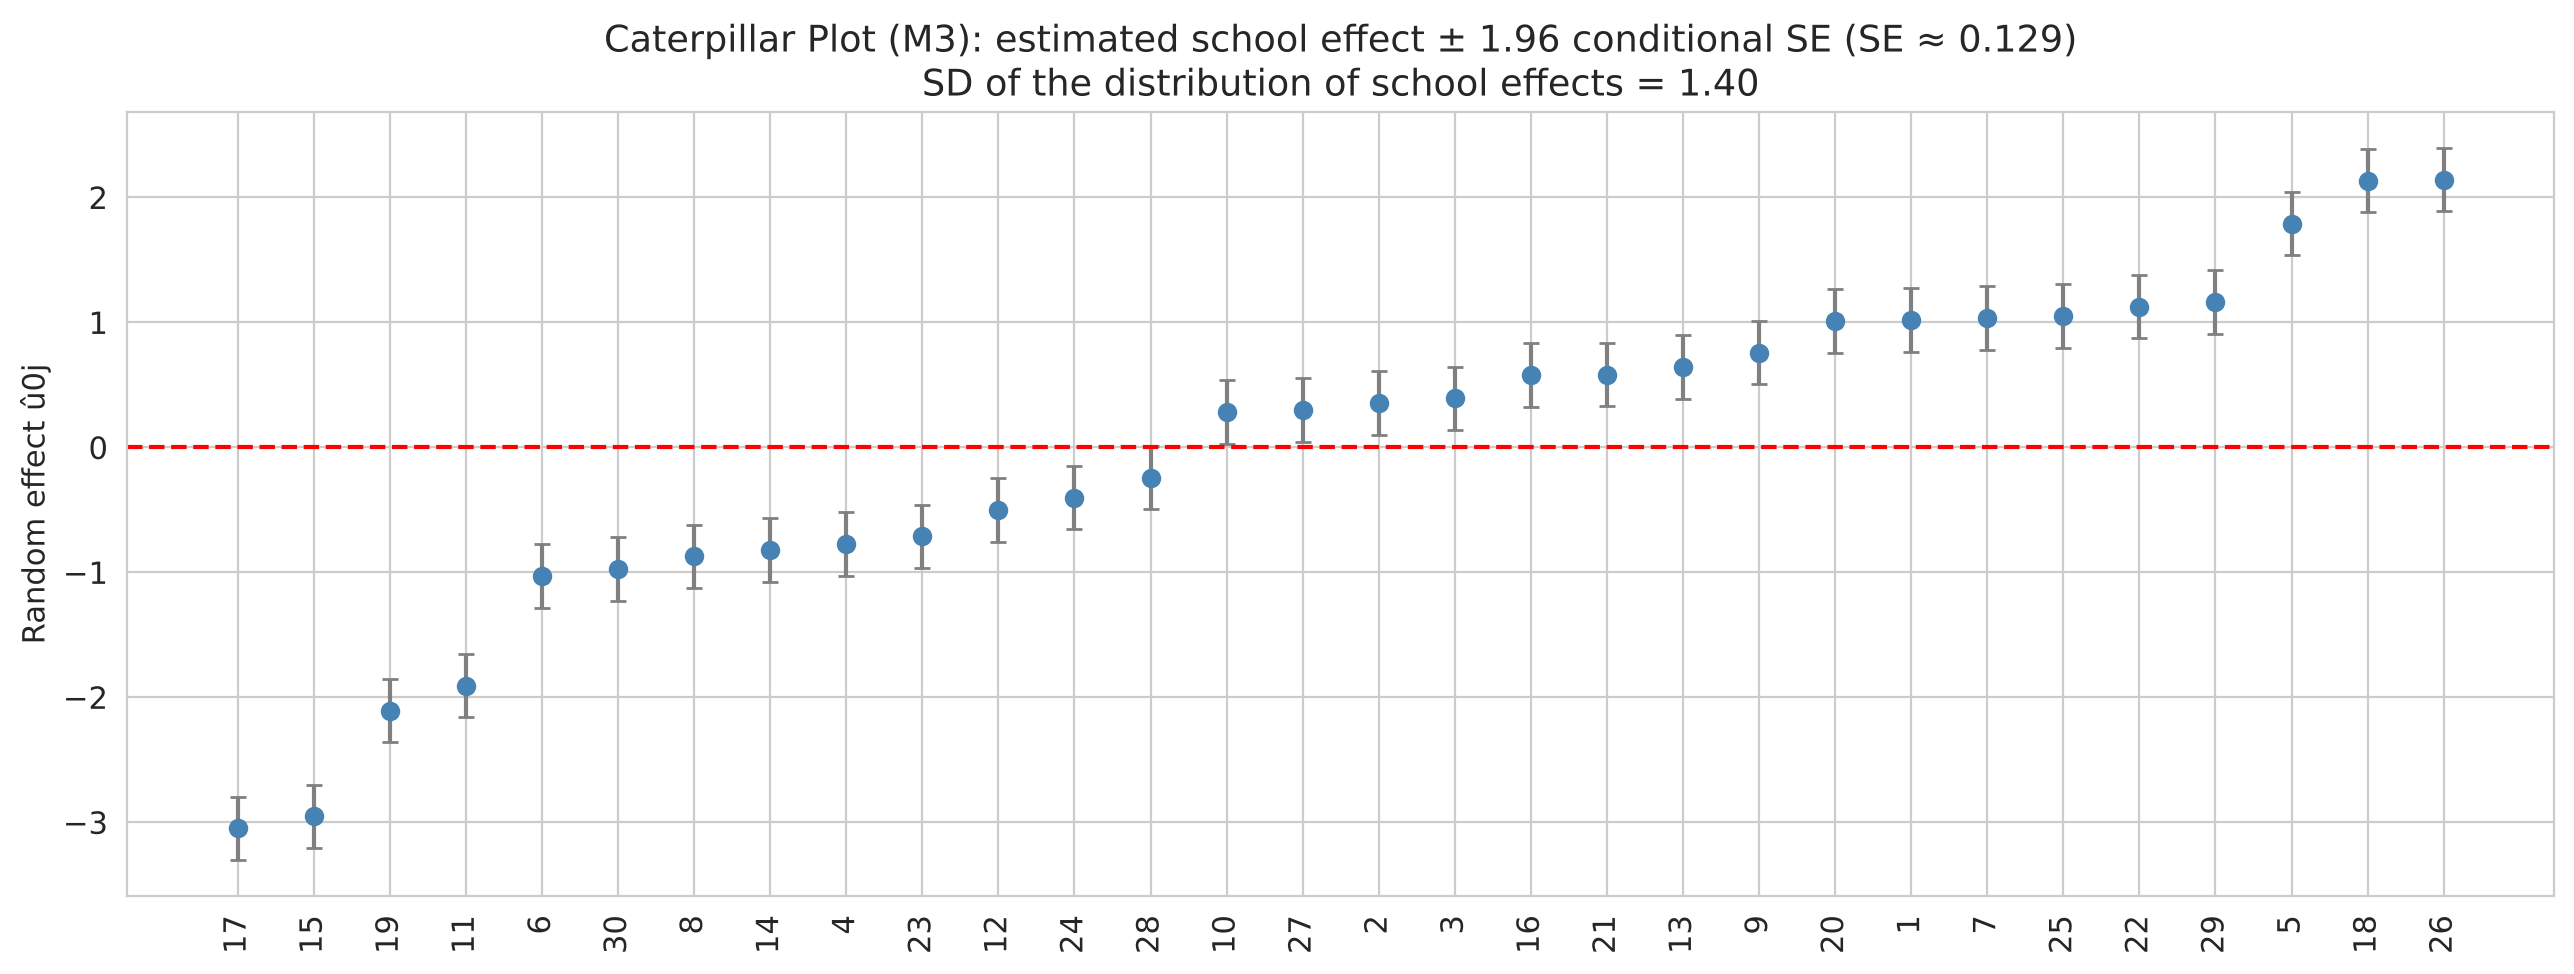

29 of 30 schools differ significantly from the average school (interval excludes 0).
Note: this conditional SE is an approximation (it ignores uncertainty in the estimates of τ00 and the fixed effects).


In [23]:
# 🔧 Caterpillar: per-school intervals use the conditional (BLUP) SE (balanced design, n_j = 30)
n_j = 30
se_cond = np.sqrt(tau00_m3 * sigma2_m3 / (sigma2_m3 + n_j * tau00_m3))
re_df = u.reset_index(); re_df.columns = ['school_id','u0j']
re_df = re_df.sort_values('u0j').reset_index(drop=True)
re_df['lo'] = re_df['u0j'] - 1.96*se_cond
re_df['hi'] = re_df['u0j'] + 1.96*se_cond

plt.figure(figsize=(13,5))
plt.errorbar(re_df.index, re_df['u0j'], yerr=1.96*se_cond, fmt='o', color='steelblue', ecolor='gray', capsize=3)
plt.axhline(0, color='red', ls='--')
plt.xticks(re_df.index, re_df['school_id'], rotation=90)
plt.ylabel('Random effect û0j')
plt.title(f'Caterpillar Plot (M3): estimated school effect ± 1.96 conditional SE (SE ≈ {se_cond:.3f})\n'
          f'SD of the distribution of school effects = {np.sqrt(tau00_m3):.2f}')
plt.tight_layout(); plt.show()
n_sig = ((re_df['lo']>0)|(re_df['hi']<0)).sum()
print(f"{n_sig} of 30 schools differ significantly from the average school (interval excludes 0).")
print("Note: this conditional SE is an approximation (it ignores uncertainty in the estimates of τ00 and the fixed effects).")

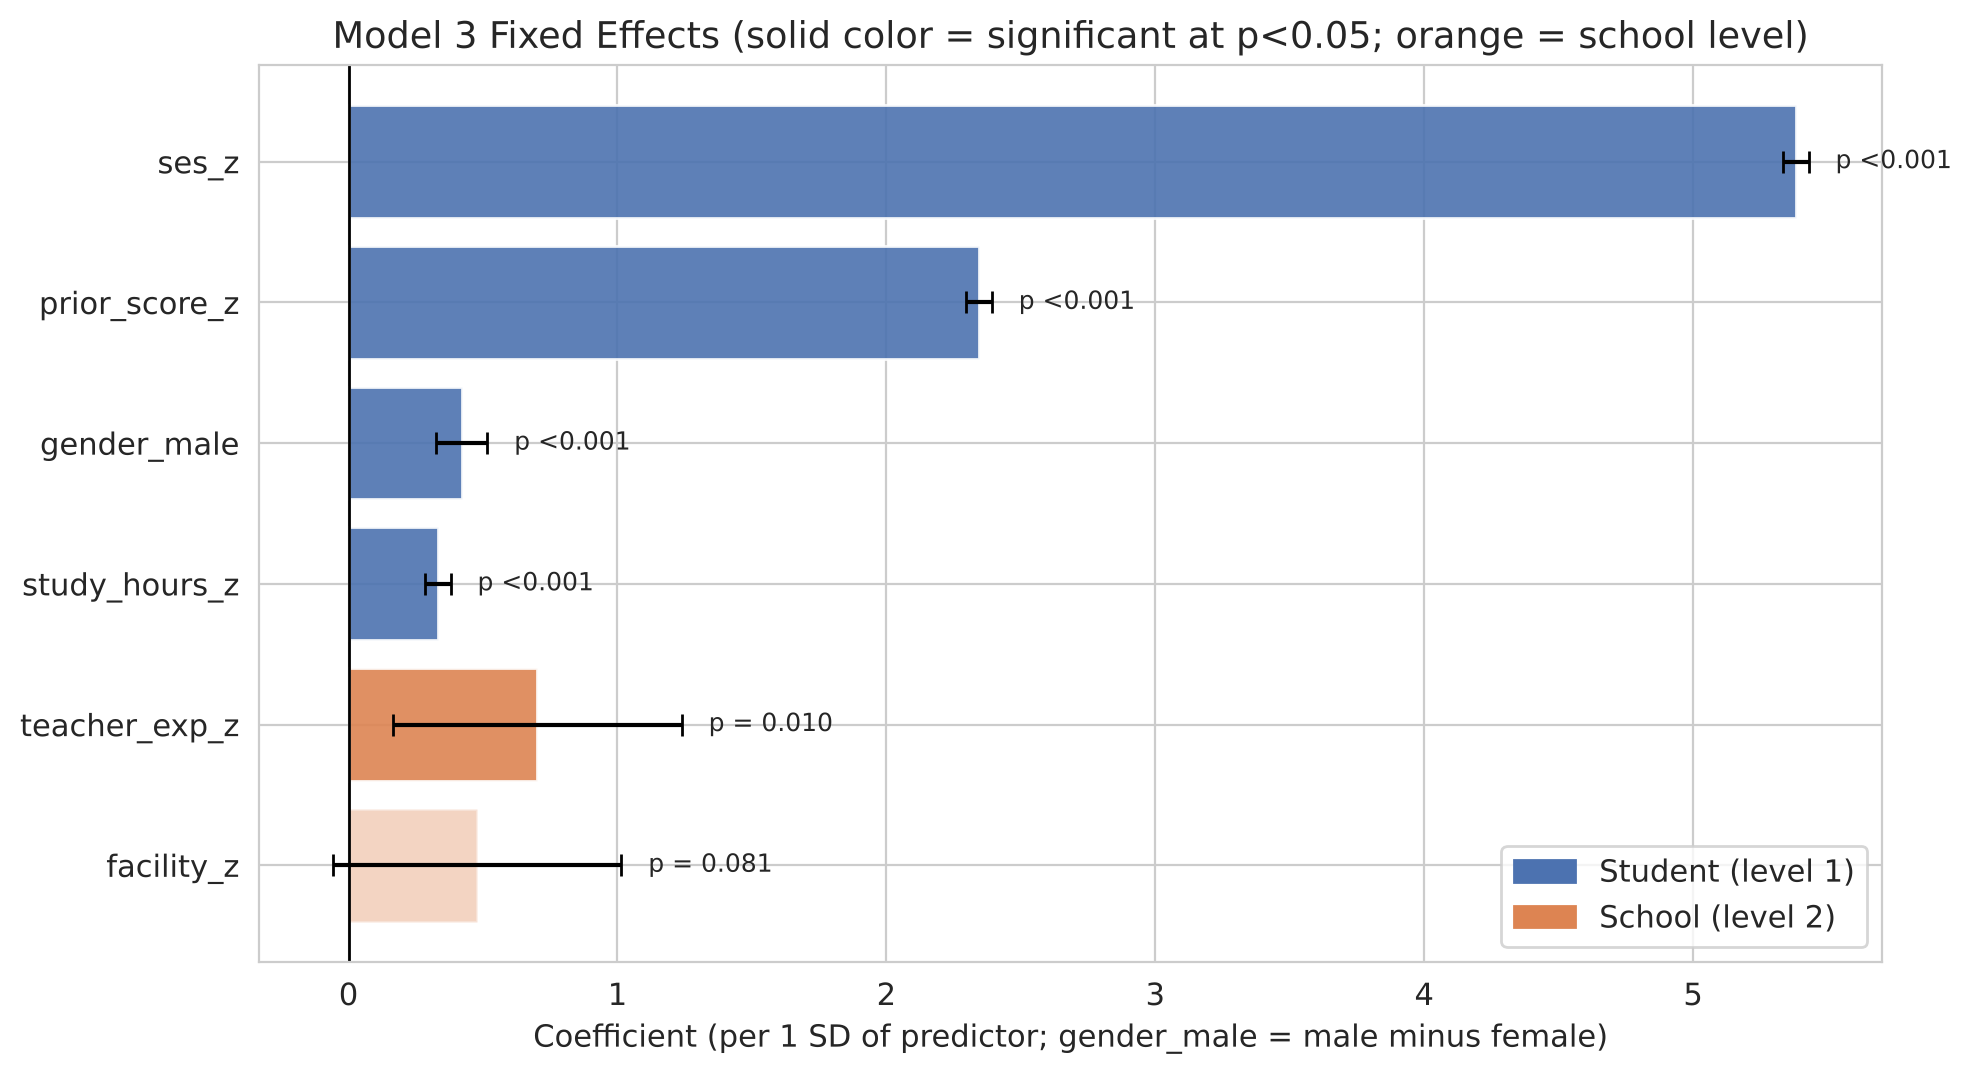

In [24]:
# 🔧 Fixed effects of M3, separated by student vs school level, with p-values
coef_df = pd.DataFrame({'coef': m3.fe_params, 'se': m3.bse_fe, 'pval': m3.pvalues[m3.fe_params.index]}).drop('Intercept')
coef_df['level'] = np.where(coef_df.index.isin(['facility_z','teacher_exp_z']), 'School (level 2)', 'Student (level 1)')
coef_df = coef_df.sort_values(['level','coef'])

fig, ax = plt.subplots(figsize=(10,5.5))
colors = {'Student (level 1)':'#4C72B0', 'School (level 2)':'#DD8452'}
ypos = np.arange(len(coef_df))
for y, (name, r) in zip(ypos, coef_df.iterrows()):
    ax.barh(y, r['coef'], xerr=1.96*r['se'], color=colors[r['level']],
            alpha=.9 if r['pval']<0.05 else .35, capsize=4)
    ax.text(r['coef'] + np.sign(r['coef'])*(1.96*r['se']+0.1), y,
            f"p {'<0.001' if r['pval']<0.001 else '= '+format(r['pval'],'.3f')}", va='center', fontsize=9)
ax.set_yticks(ypos); ax.set_yticklabels(coef_df.index)
ax.axvline(0, color='black', lw=1)
ax.set_xlabel('Coefficient (per 1 SD of predictor; gender_male = male minus female)')
ax.set_title('Model 3 Fixed Effects (solid color = significant at p<0.05; orange = school level)')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=l) for l, c in colors.items()], loc='lower right')
plt.tight_layout(); plt.show()

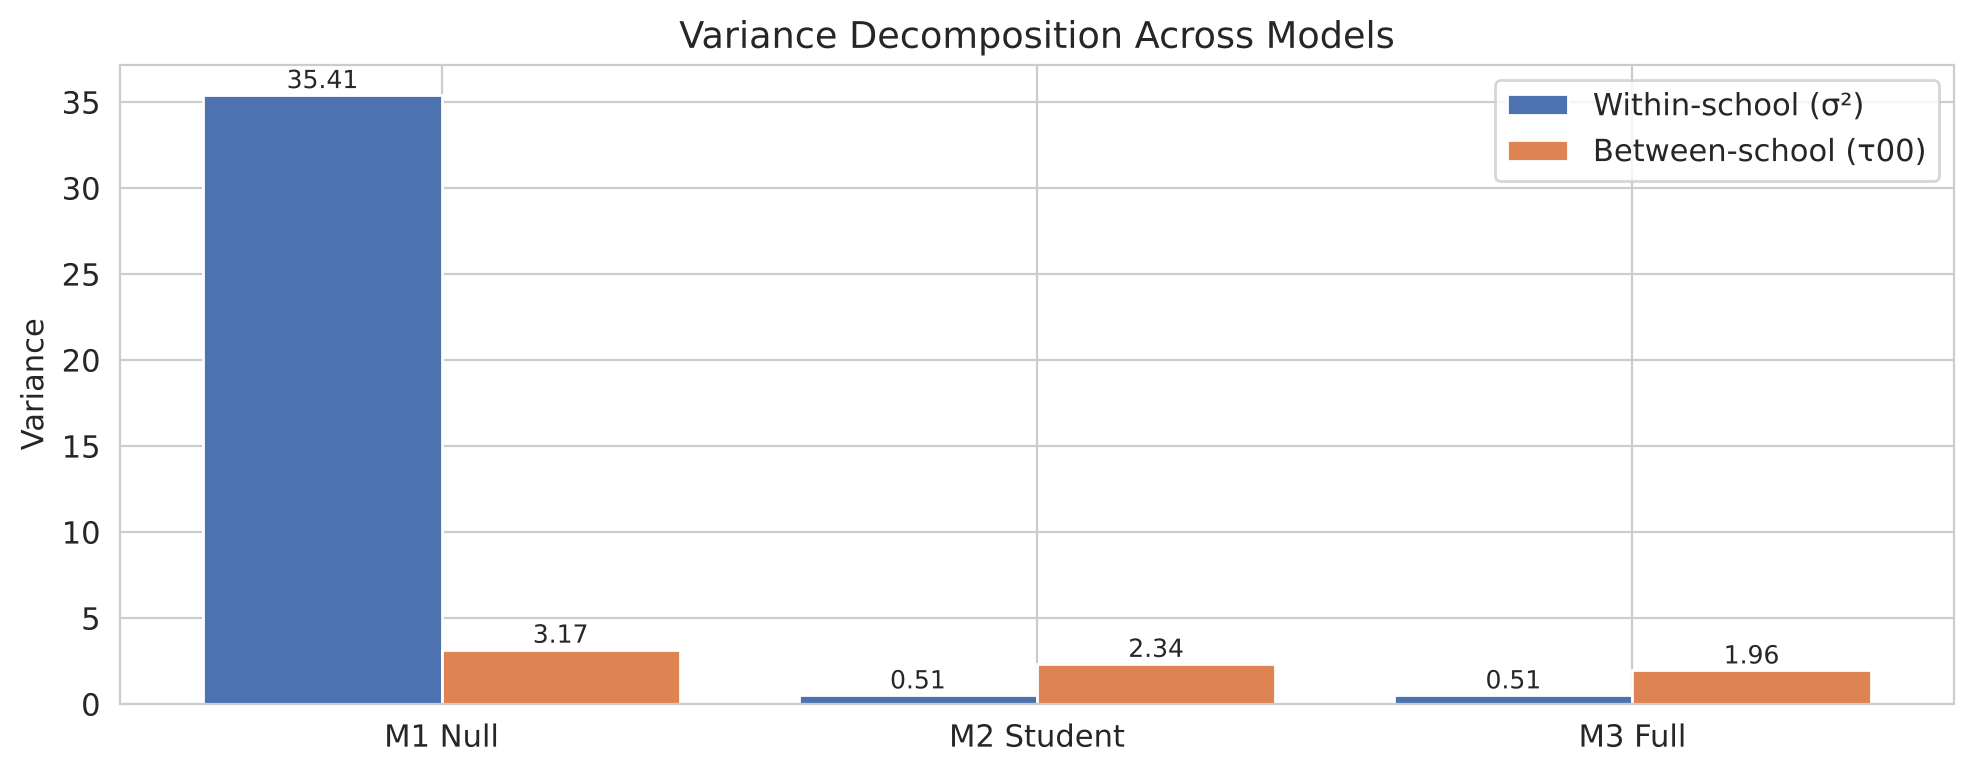

In [25]:
fig, ax = plt.subplots(figsize=(10,4))
models  = ['M1 Null','M2 Student','M3 Full']
within  = [sigma2_null, sigma2_m2, sigma2_m3]
between = [tau00_null, tau00_m2, tau00_m3]
x = np.arange(3)
ax.bar(x-0.2, within,  0.4, label='Within-school (σ²)',  color='#4C72B0')
ax.bar(x+0.2, between, 0.4, label='Between-school (τ00)', color='#DD8452')
for xi, w, b in zip(x, within, between):
    ax.text(xi-0.2, w+0.4, f'{w:.2f}', ha='center', fontsize=9); ax.text(xi+0.2, b+0.4, f'{b:.2f}', ha='center', fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(models); ax.set_ylabel('Variance')
ax.set_title('Variance Decomposition Across Models'); ax.legend(); plt.tight_layout(); plt.show()

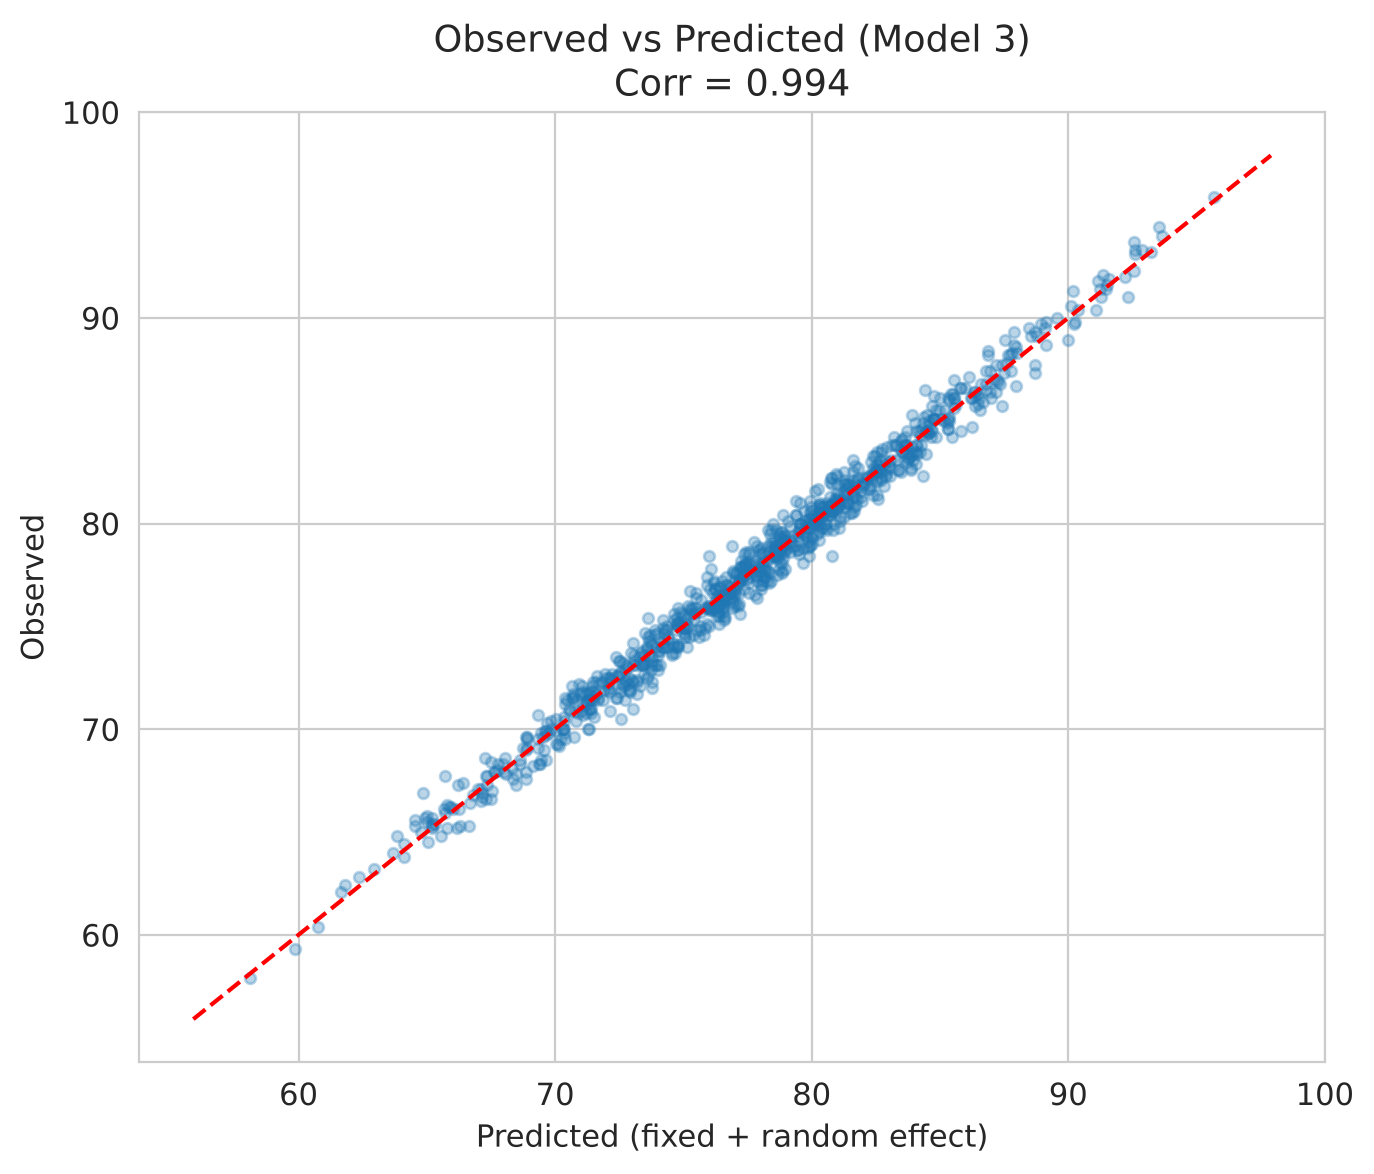

In [26]:
df['pred_m3'] = m3.fittedvalues
plt.figure(figsize=(7,6))
plt.scatter(df['pred_m3'], df['math_score'], alpha=.3, s=15)
lims = [df['math_score'].min()-2, df['math_score'].max()+2]
plt.plot(lims, lims, 'r--')
plt.xlabel('Predicted (fixed + random effect)'); plt.ylabel('Observed')
plt.title(f'Observed vs Predicted (Model 3)\nCorr = {df["pred_m3"].corr(df["math_score"]):.3f}')
plt.tight_layout(); plt.show()

## 8. Additional Analysis: Contextual Effects (🆕, exploratory)

In [27]:
# Does the school-average of student characteristics have an effect beyond the individual effect?
for v in ['ses_z','prior_score_z','study_hours_z']:
    df[v.replace('_z','_m')] = df.groupby('school_id', observed=True)[v].transform('mean')
f4 = f3 + " + ses_m + prior_score_m + study_hours_m"
m_ctx = fit_model(f4)
print(m_ctx.summary())
tau00_ctx = float(m_ctx.cov_re.iloc[0,0])
print(f"\nτ00 M3 = {tau00_m3:.3f} → τ00 (contextual model) = {tau00_ctx:.3f}")

          Mixed Linear Model Regression Results
Model:             MixedLM Dependent Variable: math_score
No. Observations:  900     Method:             REML      
No. Groups:        30      Scale:              0.5069    
Min. group size:   30      Log-Likelihood:     -1044.3149
Max. group size:   30      Converged:          Yes       
Mean group size:   30.0                                  
---------------------------------------------------------
              Coef.  Std.Err.    z    P>|z| [0.025 0.975]
---------------------------------------------------------
Intercept     77.588    0.246 315.059 0.000 77.105 78.070
prior_score_z  2.345    0.024  97.405 0.000  2.298  2.393
ses_z          5.382    0.024 222.883 0.000  5.334  5.429
study_hours_z  0.333    0.024  13.830 0.000  0.286  0.380
gender_male    0.422    0.048   8.730 0.000  0.327  0.516
facility_z     0.489    0.271   1.806 0.071 -0.042  1.020
teacher_exp_z  0.711    0.271   2.623 0.009  0.180  1.242
ses_m          2.663    

**Interpretation.** The school-mean coefficients (`ses_m`, etc.) show whether a school's student composition is associated with scores beyond the effect of individual SES. These results are **exploratory** (only 30 schools, effects tend to be borderline), so they are presented as a direction for further research, not as a main finding.

## 9. Model Summary Table (🆕)

In [28]:
def stars(p): return '***' if p<.001 else '**' if p<.01 else '*' if p<.05 else ''
labels = {'Intercept':'Intercept','prior_score_z':'Prior score (z)','ses_z':'SES (z)',
          'study_hours_z':'Study hours (z)','gender_male':'Gender: male',
          'facility_z':'Facility (z)','teacher_exp_z':'Teacher exp (z)'}
rows = {}
for k, lab in labels.items():
    row = []
    for m in (m1, m2, m3, m_rs):
        row.append(f"{m.fe_params[k]:.3f}{stars(m.pvalues[k])} ({m.bse_fe[k]:.3f})" if k in m.fe_params.index else "")
    rows[lab] = row
rows['τ00 (school intercept variance)'] = [f"{t:.3f}" for t in (tau00_null, tau00_m2, tau00_m3, tau00_rs)]
rows['τ11 (study_hours slope variance)'] = ["", "", "", f"{tau11_rs:.3f}"]
rows['ρ intercept-slope']     = ["", "", "", f"{rho_rs:.2f}"]
rows['σ² (student variance)'] = [f"{s:.3f}" for s in (sigma2_null, sigma2_m2, sigma2_m3, sigma2_rs)]
rows['ICC (null model)']      = [f"{icc_null:.3f}", "", "", ""]
rows['PVE σ² vs null (%)']    = ["", f"{pve(sigma2_m2,sigma2_null):.1f}", f"{pve(sigma2_m3,sigma2_null):.1f}", f"{pve(sigma2_rs,sigma2_null):.1f}"]
rows['PVE τ00 vs null (%)']   = ["", f"{pve(tau00_m2,tau00_null):.1f}", f"{pve(tau00_m3,tau00_null):.1f}", f"{pve(tau00_rs,tau00_null):.1f}"]
rows['R² marginal']           = [f"{r2[k][0]:.3f}" for k in ('M1','M2','M3')] + ["–"]
rows['R² conditional']        = [f"{r2[k][1]:.3f}" for k in ('M1','M2','M3')] + ["–"]
rows['AIC (ML)']              = [f"{a:.1f}" for a in aic]
rows['BIC (ML)']              = [f"{b:.1f}" for b in bic]
rows['N students / N schools'] = ["900 / 30"]*4
final_tbl = pd.DataFrame(rows, index=['M1 Null','M2 Student','M3 Full','M4 +slope study']).T
print("Coefficient (SE); * p<.05, ** p<.01, *** p<.001")
display(final_tbl) if 'display' in globals() else print(final_tbl)

Coefficient (SE); * p<.05, ** p<.01, *** p<.001
                                            M1 Null         M2 Student            M3 Full    M4 +slope study
Intercept                         77.787*** (0.381)  77.588*** (0.281)  77.588*** (0.258)  77.575*** (0.252)
Prior score (z)                                       2.345*** (0.024)   2.345*** (0.024)   2.341*** (0.021)
SES (z)                                               5.382*** (0.024)   5.382*** (0.024)   5.376*** (0.021)
Study hours (z)                                       0.333*** (0.024)   0.332*** (0.024)   0.310*** (0.073)
Gender: male                                          0.421*** (0.048)   0.422*** (0.048)   0.467*** (0.041)
Facility (z)                                                                0.478 (0.274)   0.385*** (0.108)
Teacher exp (z)                                                            0.702* (0.274)   0.457*** (0.112)
τ00 (school intercept variance)               3.165              2.340          

## 10. Conclusions

In [29]:
# 🔧 All numbers are taken from the fitted-model variables (nothing hard-coded)
b2, p2, b3, p3 = m2.fe_params, m2.pvalues, m3.fe_params, m3.pvalues
print("="*65); print("CONCLUSIONS"); print("="*65)
print(f"""
[Q1] Variance decomposition
     ICC = {icc_null*100:.2f}% → about {icc_null*100:.1f}% of the variation in mathematics scores comes from differences
     BETWEEN schools, and {100-icc_null*100:.1f}% from differences BETWEEN students within schools.
     LRT for between-school variance: p = {fp(p_q1)}. Design effect = {deff:.2f} → a multilevel model is required.

[Q2] Student characteristics (Model 2, effects per 1 SD)
     prior_score_z  {b2['prior_score_z']:+.3f}  (p {fp(p2['prior_score_z'])})
     ses_z          {b2['ses_z']:+.3f}  (p {fp(p2['ses_z'])})
     study_hours_z  {b2['study_hours_z']:+.3f}  (p {fp(p2['study_hours_z'])})
     gender_male    {b2['gender_male']:+.3f}  (p {fp(p2['gender_male'])})
     σ² falls {sigma2_null:.2f} → {sigma2_m2:.3f} ({pve(sigma2_m2, sigma2_null):.1f}% of within-school variation explained).
     SES is the strongest predictor, followed by prior score. Study hours and gender are significant but small.

[Q3] School characteristics (Model 3, effects per 1 SD)
     facility_z     {b3['facility_z']:+.3f}  (p {fp(p3['facility_z'])})  → {'significant' if p3['facility_z']<.05 else 'insufficient evidence at α=5%'}
     teacher_exp_z  {b3['teacher_exp_z']:+.3f}  (p {fp(p3['teacher_exp_z'])})  → {'significant' if p3['teacher_exp_z']<.05 else 'insufficient evidence at α=5%'}
     Joint test (LRT, 2 df): χ² = {lrt_q3:.2f}, p = {fp(p_q3)}.
     τ00 falls {tau00_m2:.3f} → {tau00_m3:.3f} ({pve(tau00_m3, tau00_m2):.1f}% additional between-school variation explained).
     Robustness (4 specifications): teacher_exp significant in {n_sig_te}/4, facility in {n_sig_fa}/4 specifications.
     → teacher_exp: ROBUST finding. facility: positive direction but evidence NOT YET CONSISTENT (specification-dependent).
     Note: with only 30 schools, school-level power is limited; "not significant" ≠ "no effect".

[Q4] Remaining between-school variation
     residual τ00 = {tau00_m3:.3f} (SE {se_tau3:.3f}); LRT vs OLS p = {fp(p_q4)} → {'STILL PRESENT' if p_q4<.05 else 'not shown to exist'}: between-school variation that remains unexplained.
     Total τ00 explained = {pve(tau00_m3, tau00_null):.1f}%; {100*tau00_m3/tau00_null:.1f}% of the initial τ00 remains
     (≈ {100*tau00_m3/total_null:.1f}% of the total null-model variance).
     Possible unmeasured factors: school culture, leadership, parental support, etc.

[Additional finding: the study-hours effect is not uniform across schools (Model 4)]
     Random slope for study_hours: LRT = {lrt_rs:.1f}, ΔAIC = {aic[2]-aic[3]:.1f} (M4 fits far better than M3).
     Mean effect = {m_rs.fe_params['study_hours_z']:+.3f} per SD, SD across schools = {np.sqrt(tau11_rs):.3f}; intercept-slope correlation ρ = {rho_rs:.2f}.
     → The benefit of study time differs across schools (it can be zero or negative in some) and is tied to
       unmeasured school-level factors. Under M4, τ00 = {tau00_rs:.3f} (SE {se_tau_rs:.3f}); random-effect block test p = {fp(p_q4_rs)}
       → between-school variation remains (the answer to Q4 does not change).

[Intervention recommendations]
     • Student level: top priority (SES and prior ability). Examples: tutoring/remedial support and socioeconomic assistance.
     • School level: improve teacher quality/experience (robust); facilities are positive but not yet consistent.
     • Study time: its effect depends on school context, so 'add more study hours' programs should be tailored per school.
     • Because between-school variation remains, use a COMBINED approach and investigate other school-level factors.

[Limitations]
     Observational data (association, not causation); only 30 schools; school-level effects are sensitive to particular schools
     (see LOSO and robustness checks); normality and linearity hold, whereas homogeneity of variance across schools
     holds only after the random slope for study hours is included (M4); M4 inference relies on an intercept-slope
     correlation estimated from just 30 schools.
""")
print("✅ Analysis complete.")

CONCLUSIONS

[Q1] Variance decomposition
     ICC = 8.21% → about 8.2% of the variation in mathematics scores comes from differences
     BETWEEN schools, and 91.8% from differences BETWEEN students within schools.
     LRT for between-school variance: p = <0.001. Design effect = 3.38 → a multilevel model is required.

[Q2] Student characteristics (Model 2, effects per 1 SD)
     prior_score_z  +2.345  (p <0.001)
     ses_z          +5.382  (p <0.001)
     study_hours_z  +0.333  (p <0.001)
     gender_male    +0.421  (p <0.001)
     σ² falls 35.41 → 0.507 (98.6% of within-school variation explained).
     SES is the strongest predictor, followed by prior score. Study hours and gender are significant but small.

[Q3] School characteristics (Model 3, effects per 1 SD)
     facility_z     +0.478  (p 0.081)  → insufficient evidence at α=5%
     teacher_exp_z  +0.702  (p 0.010)  → significant
     Joint test (LRT, 2 df): χ² = 7.44, p = 0.024.
     τ00 falls 2.340 → 1.957 (16.3% additional b

## Executive Summary (🆕)
Differences in mathematics achievement come **mostly from differences between students** and only to a **smaller extent from differences between schools**. Student characteristics, especially socioeconomic status and prior ability, explain almost all of the within-school variation. At the school level, teacher experience is positively associated with scores in every model specification (a robust finding), while evidence for facilities is not yet consistent (it depends on the specification). The effect of study time is **not uniform across schools**, which signals unmeasured school-level factors. After accounting for all variables, **between-school differences remain unexplained**. Recommendation: focus interventions mainly on **students**, complemented by strengthening **teacher quality**, tailoring study-time programs to each school, and further research into other unmeasured school factors.

*Note: read the exact figures from the Conclusions cell above; this summary is qualitative.*